# Predict Future Sales — Exploratory Data Analysis (EDA)

**Proyecto #1 · Product Development**

**Dataset:** [Predict Future Sales](https://www.kaggle.com/competitions/competitive-data-science-predict-future-sales/data)
(Kaggle). Ventas diarias de la cadena rusa **1C Company** entre enero 2013 y octubre 2015.

**Objetivo de negocio:** la competencia pide predecir las **ventas mensuales de cada par
tienda–producto para noviembre de 2015**. Este notebook es la etapa de **análisis exploratorio**:
entender los datos, validar su calidad, tomar decisiones de limpieza justificadas y descubrir los
patrones que deben guiar la etapa de *forecasting*.

### Contenido (sigue la numeración del enunciado)

| Sección | Tema |
|---|---|
| 0 | Configuración del entorno |
| 1 | Estructura del proyecto |
| 2 | Comprensión inicial del dataset |
| 3 | Validación de la estructura de los datos |
| 4 | Valores faltantes, inválidos y duplicados (+ limpieza) |
| 5 | Análisis descriptivo general |
| 6 | Exploración temporal |
| 7 | Análisis comparativo entre sucursales y productos |
| 8 | Visualizaciones clave |
| 9 | Autocorrelación (ACF) y autocorrelación parcial (PACF) |
| 10 | Insights y conclusiones |

> Todas las figuras se guardan además en `reports/figures/`. Las funciones reutilizables (carga,
> traducción de catálogos, limpieza y gráficas) viven en el paquete `predict_future_sales`, para
> que las etapas siguientes del proyecto las importen sin duplicar código.

## 0. Configuración del entorno

Se importan las librerías del análisis:

- **pandas / numpy**: manipulación de datos y cálculos vectorizados.
- **matplotlib / seaborn**: visualización.
- **statsmodels**: descomposición de series, prueba de estacionariedad (ADF) y funciones ACF/PACF.
- **predict_future_sales**: paquete del proyecto (estructura Cookiecutter) con rutas centralizadas
  (`config.py`), carga/limpieza de datos (`dataset.py`) y utilidades de gráficas (`plots.py`).

In [1]:
# --- Librerías estándar y de terceros -------------------------------------------------------
import os
os.environ["LOGURU_LEVEL"] = "WARNING"      # silencia el log informativo del paquete (config.py)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display, Markdown
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import acf, adfuller, pacf

# --- Paquete del proyecto -------------------------------------------------------------------
from predict_future_sales.config import FIGURES_DIR, INTERIM_DATA_DIR, PROCESSED_DATA_DIR, RAW_DATA_DIR
from predict_future_sales.dataset import (
    CATEGORY_NAMES_ES, MAX_ITEM_CNT_DAY, MAX_ITEM_PRICE, SHOP_DUPLICATES,
    add_catalog_info, build_catalogs, clean_sales, load_raw_data,
)
from predict_future_sales.plots import (
    COLOR_ACCENT, COLOR_MAIN, COLOR_MUTED, block_label, date_formatter_es, plot_acf_pacf, save_fig,
    set_style, thousands_formatter,
)

# --- Opciones de visualización --------------------------------------------------------------
set_style()                                    # estilo común de todas las gráficas
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)  # separador de miles en tablas

print("Datos crudos en:", RAW_DATA_DIR)
print("Figuras en:     ", FIGURES_DIR)

Datos crudos en: C:\Users\cesar\OneDrive\Escritorio\maestria\Segundo año\Cuarto trimeste\Product Development\proyecto1\Predict Future Sales\data\raw
Figuras en:      C:\Users\cesar\OneDrive\Escritorio\maestria\Segundo año\Cuarto trimeste\Product Development\proyecto1\Predict Future Sales\reports\figures


## 1. Estructura del proyecto y repositorio

El proyecto se generó con la plantilla oficial **Cookiecutter Data Science v2** (`ccds`):

```
Predict Future Sales/
├── data/{raw, interim, processed, external}   <- raw = CSV originales de Kaggle (no versionados)
├── notebooks/01_exploratory_data_analysis.ipynb
├── predict_future_sales/                      <- paquete Python (config, dataset, plots, ...)
├── reports/figures/                           <- figuras exportadas por este notebook
├── environment.yml / requirements.txt          <- entorno reproducible
└── README.md, Makefile, pyproject.toml, .gitignore
```

- Los archivos de Kaggle (~100 MB) se colocan en `data/raw/` y están excluidos en `.gitignore`.
- El repositorio git / GitHub y los *screenshots* del `pull` de cada integrante se documentan en el
  `README.md` del repositorio.

## 2. Comprensión inicial del dataset

### 2a. Carga de los archivos y primeras filas

`load_raw_data()` lee los 5 archivos del enunciado desde `data/raw/` y devuelve un diccionario
de DataFrames. `sample_submission.csv` solo muestra el formato de entrega de Kaggle, por lo que se
lee aparte.

In [2]:
raw = load_raw_data()                       # {"sales", "items", "categories", "shops", "test"}
sales_raw = raw["sales"]
items, categories, shops, test = raw["items"], raw["categories"], raw["shops"], raw["test"]
sample_submission = pd.read_csv(RAW_DATA_DIR / "sample_submission.csv")

# Primeras filas de cada tabla
for name, df_ in [("sales_train.csv", sales_raw), ("items.csv", items),
                  ("item_categories.csv", categories), ("shops.csv", shops),
                  ("test.csv", test), ("sample_submission.csv", sample_submission)]:
    display(Markdown(f"**{name}**"))
    display(df_.head())

**sales_train.csv**

,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
0,02.01.2013,0,59,22154,999.00,1.00
1,03.01.2013,0,25,2552,899.00,1.00
2,05.01.2013,0,25,2552,899.00,-1.00
3,06.01.2013,0,25,2554,"1,709.05",1.00
4,15.01.2013,0,25,2555,"1,099.00",1.00


**items.csv**

,item_name,item_id,item_category_id
0,! ВО ВЛАСТИ НАВАЖДЕНИЯ (ПЛАСТ.) D,0,40
1,!ABBYY FineReader 12 Professional Edition Full...,1,76
2,***В ЛУЧАХ СЛАВЫ (UNV) D,2,40
3,***ГОЛУБАЯ ВОЛНА (Univ) D,3,40
4,***КОРОБКА (СТЕКЛО) D,4,40


**item_categories.csv**

,item_category_name,item_category_id
0,PC - Гарнитуры/Наушники,0
1,Аксессуары - PS2,1
2,Аксессуары - PS3,2
3,Аксессуары - PS4,3
4,Аксессуары - PSP,4


... (2 outputs left out)

**test.csv**

,ID,shop_id,item_id
0,0,5,5037
1,1,5,5320
2,2,5,5233
3,3,5,5232
4,4,5,5268


**sample_submission.csv**

,ID,item_cnt_month
0,0,0.50
1,1,0.50
2,2,0.50
3,3,0.50
4,4,0.50


Los nombres de productos, categorías y tiendas están en **ruso**. Para que las gráficas sean
legibles, el paquete incluye una traducción al español de las 84 categorías y de la ciudad de cada
tienda (`build_catalogs`). Además se derivan dos atributos útiles:

- `category_group`: grupo de alto nivel de la categoría (la parte antes de `" - "`, p. ej. *Juegos*,
  *Cine*, *Música*).
- `shop_type`: tipo de tienda según su nombre (*Centro comercial*, *Calle*, *Online*,
  *Itinerante*, *Liquidación*).

In [3]:
items_full, shops_full = build_catalogs(items, categories, shops)

display(items_full.sample(5, random_state=42))
display(shops_full.head(8))

,item_name,item_id,item_category_id,item_category_name,category_es,category_group
11068,ДИК ТРЭЙСИ (BD),11068,37,Кино - Blu-Ray,Cine - Blu-Ray,Cine
4463,"Legends of Aethereus [PC, Цифровая версия]",4463,31,Игры PC - Цифра,Juegos PC - Digital,Juegos PC
15506,Мягкая игрушка-подушка Маша и Медведь Антистре...,15506,63,Подарки - Мягкие игрушки,Regalos - Peluches,Regalos
21995,"Штрафбат (СофтКлаб) [PC, Цифровая версия]",21995,31,Игры PC - Цифра,Juegos PC - Digital,Juegos PC
1572,Assassin's Creed: Откровения (Essentials) [PS3...,1572,19,Игры - PS3,Juegos - PS3,Juegos


,shop_name,shop_id,city,shop_type,shop_label
0,"!Якутск Орджоникидзе, 56 фран",0,Yakutsk,Calle,0 · Yakutsk
1,"!Якутск ТЦ ""Центральный"" фран",1,Yakutsk,Centro comercial,1 · Yakutsk
2,"Адыгея ТЦ ""Мега""",2,Adigueya,Centro comercial,2 · Adigueya
3,"Балашиха ТРК ""Октябрь-Киномир""",3,Balashikha,Centro comercial,3 · Balashikha
4,"Волжский ТЦ ""Волга Молл""",4,Volzhski,Centro comercial,4 · Volzhski
5,"Вологда ТРЦ ""Мармелад""",5,Vólogda,Centro comercial,5 · Vólogda
6,"Воронеж (Плехановская, 13)",6,Vorónezh,Calle,6 · Vorónezh
7,"Воронеж ТРЦ ""Максимир""",7,Vorónezh,Centro comercial,7 · Vorónezh


### 2b. Tamaño de cada tabla

In [4]:
sizes = pd.DataFrame(
    {
        "filas": [len(d) for d in (sales_raw, items, categories, shops, test, sample_submission)],
        "columnas": [d.shape[1] for d in (sales_raw, items, categories, shops, test, sample_submission)],
        "memoria_MB": [d.memory_usage(deep=True).sum() / 1e6
                       for d in (sales_raw, items, categories, shops, test, sample_submission)],
    },
    index=["sales_train", "items", "item_categories", "shops", "test", "sample_submission"],
)
display(sizes.style.format({"filas": "{:,}", "columnas": "{:,}", "memoria_MB": "{:,.1f}"}))

print(f"Tiendas en sales_train:   {sales_raw.shop_id.nunique():>6,} de {len(shops)} en el catálogo")
print(f"Productos en sales_train: {sales_raw.item_id.nunique():>6,} de {len(items):,} en el catálogo")
print(f"Tiendas en test:          {test.shop_id.nunique():>6,}")
print(f"Productos en test:        {test.item_id.nunique():>6,}")

,filas,columnas,memoria_MB
sales_train,"2,935,849",6,290.6
items,"22,170",3,3.5
item_categories,84,2,0.0
shops,60,2,0.0
test,"214,200",3,5.1
sample_submission,"214,200",2,3.4


Tiendas en sales_train:       60 de 60 en el catálogo
Productos en sales_train: 21,807 de 22,170 en el catálogo
Tiendas en test:              42
Productos en test:         5,100


**Interpretación.**

- `sales_train` es la tabla de hechos: **2,935,849 transacciones** diarias. Las demás son catálogos
  pequeños (22,170 productos, 84 categorías, 60 tiendas).
- **No todo el catálogo tiene ventas**: 363 de los 22,170 productos nunca se vendieron en el periodo
  de entrenamiento.
- `test.csv` tiene **214,200 filas = 42 tiendas × 5,100 productos**. Es decir, Kaggle pide predecir
  la **cuadrícula completa** tienda × producto, no solo los pares que efectivamente vendieron. Esto
  implica que muchas predicciones correctas serán 0 (ver sección 10b).

### 2c. Diccionario de columnas y variable objetivo

| Columna | Archivo | Tipo | Descripción |
|---|---|---|---|
| `date` | sales_train | fecha | Día de la transacción (texto `dd.mm.aaaa` en el original) |
| `date_block_num` | sales_train | entero ordinal | Mes consecutivo: 0 = ene-2013 … 33 = oct-2015 |
| `shop_id` | sales_train, shops, test | categórica (ID) | Identificador de la tienda |
| `item_id` | sales_train, items, test | categórica (ID) | Identificador del producto |
| `item_price` | sales_train | numérica continua | Precio unitario en esa transacción (rublos) |
| `item_cnt_day` | sales_train | numérica discreta | Unidades vendidas ese día (negativo = devolución) |
| `item_name` | items | texto | Nombre del producto (ruso) |
| `item_category_id` | items, item_categories | categórica (ID) | Categoría del producto (84 categorías) |
| `item_category_name` | item_categories | texto | Nombre de la categoría, formato `Grupo - Subgrupo` (ruso) |
| `shop_name` | shops | texto | Nombre de la tienda: ciudad + centro comercial (ruso) |
| `ID` | test | entero | Identificador de la fila a predecir (par tienda–producto) |

**Variable objetivo.** La competencia no pide predecir `item_cnt_day`, sino
**`item_cnt_month`**: la suma de `item_cnt_day` de un par (`shop_id`, `item_id`) en un mes. Kaggle
evalúa con RMSE y **recorta el valor real al rango [0, 20]**. Para el análisis de negocio también se
construye el **ingreso** `revenue = item_price × item_cnt_day`, ya que el dataset no trae ventas en
dinero.

La celda siguiente construye el objetivo mensual para ver su forma real.

In [5]:
# Objetivo mensual: suma de unidades por (mes, tienda, producto)
target_monthly = (
    sales_raw.groupby(["date_block_num", "shop_id", "item_id"], as_index=False)["item_cnt_day"].sum()
    .rename(columns={"item_cnt_day": "item_cnt_month"})
)
display(target_monthly.head())
display(target_monthly["item_cnt_month"].describe(percentiles=[.25, .5, .75, .9, .99]).to_frame().T)

share_gt20 = (target_monthly["item_cnt_month"] > 20).mean()
share_neg = (target_monthly["item_cnt_month"] < 0).mean()
print(f"Pares-mes con venta > 20 (se recortan a 20 en la evaluación): {share_gt20:.2%}")
print(f"Pares-mes con venta neta negativa (se recortan a 0):         {share_neg:.3%}")

,date_block_num,shop_id,item_id,item_cnt_month
0,0,0,32,6.00
1,0,0,33,3.00
2,0,0,35,1.00
3,0,0,43,1.00
4,0,0,51,2.00


,count,mean,std,min,25%,50%,75%,90%,99%,max
item_cnt_month,"1,609,124.00",2.27,8.65,-22.00,1.00,1.00,2.00,4.00,17.00,"2,253.00"


Pares-mes con venta > 20 (se recortan a 20 en la evaluación): 0.71%
Pares-mes con venta neta negativa (se recortan a 0):         0.057%


**Interpretación.**

- El objetivo mensual es **muy pequeño y concentrado en 1**: mediana = 1, percentil 75 = 2 y
  percentil 99 = 17 unidades. La media (2.27) está inflada por una cola larga (máximo de 2,253
  antes de limpiar).
- Solo el **0.71%** de los pares-mes supera 20 unidades y el **0.057%** es negativo, de modo que el
  recorte [0, 20] de Kaggle afecta a muy pocos registros, pero son justamente los extremos que más
  pesan en el RMSE. **En el modelado conviene recortar también el objetivo de entrenamiento a [0, 20].**
- Esta tabla solo contiene los pares-mes **con alguna transacción**; los pares-mes sin ventas (ceros)
  no existen en el archivo y habrá que generarlos para entrenar sobre una cuadrícula similar a test.

### 2d. Rango temporal de los datos

Se convierte `date` a tipo fecha (formato explícito `%d.%m.%Y` para evitar ambigüedad día/mes) y se
calcula el rango y el número de meses.

In [6]:
dates = pd.to_datetime(sales_raw["date"], format="%d.%m.%Y")
n_days = dates.dt.normalize().nunique()

print(f"Fecha mínima: {dates.min():%d-%m-%Y}")
print(f"Fecha máxima: {dates.max():%d-%m-%Y}")
print(f"Días distintos con registros: {n_days:,}  (calendario: {(dates.max() - dates.min()).days + 1:,} días)")
print(f"Meses cubiertos (date_block_num únicos): {sales_raw.date_block_num.nunique()}  "
      f"-> bloques {sales_raw.date_block_num.min()} a {sales_raw.date_block_num.max()}")
print("Mes a predecir: noviembre 2015 = date_block_num 34")

Fecha mínima: 01-01-2013
Fecha máxima: 31-10-2015
Días distintos con registros: 1,034  (calendario: 1,034 días)
Meses cubiertos (date_block_num únicos): 34  -> bloques 0 a 33
Mes a predecir: noviembre 2015 = date_block_num 34


**Interpretación.** Los datos cubren del **1-ene-2013 al 31-oct-2015**: **1,034 días** y **34 meses**
completos (`date_block_num` 0 a 33). El mes a predecir es noviembre 2015 (bloque 34). Hay registros
en todos los días del calendario: no falta ningún día a nivel cadena.

## 3. Validación de la estructura de los datos

### 3a. Tipos de datos

Se compara el tipo con el que pandas leyó cada columna contra su **tipo semántico**. Un ID es un
número entero en el archivo, pero conceptualmente es **categórico**: promediar `shop_id` no tiene
sentido.

In [7]:
semantic = {
    "date": "fecha (texto en el CSV)", "date_block_num": "ordinal temporal",
    "shop_id": "categórica (ID)", "item_id": "categórica (ID)",
    "item_price": "numérica continua", "item_cnt_day": "numérica discreta",
}
dtypes_tbl = pd.DataFrame({
    "dtype_pandas": sales_raw.dtypes.astype(str),
    "tipo_semántico": pd.Series(semantic),
    "valores_únicos": sales_raw.nunique(),
    "ejemplo": sales_raw.iloc[0],
})
display(dtypes_tbl)

for name, df_ in [("items", items), ("item_categories", categories), ("shops", shops), ("test", test)]:
    print(f"{name:16s}", dict(df_.dtypes.astype(str)))

,dtype_pandas,tipo_semántico,valores_únicos,ejemplo
date,str,fecha (texto en el CSV),1034,02.01.2013
date_block_num,int64,ordinal temporal,34,0
shop_id,int64,categórica (ID),60,59
item_id,int64,categórica (ID),21807,22154
item_price,float64,numérica continua,19993,999.00
item_cnt_day,float64,numérica discreta,198,1.00


items            {'item_name': 'str', 'item_id': 'int64', 'item_category_id': 'int64'}
item_categories  {'item_category_name': 'str', 'item_category_id': 'int64'}
shops            {'shop_name': 'str', 'shop_id': 'int64'}
test             {'ID': 'int64', 'shop_id': 'int64', 'item_id': 'int64'}


**Interpretación.**

- `date` se leyó como **texto** (`str`): hay que convertirla (3b).
- `shop_id`, `item_id` e `item_category_id` son `int64`, pero semánticamente son **categóricas**:
  no deben usarse como números continuos en un modelo lineal (sí como identificadores o con
  *encoding*).
- `item_cnt_day` se leyó como `float64` aunque es un conteo entero (incluye negativos por
  devoluciones). `item_price` es continua con 19,993 valores distintos: el mismo producto cambia de
  precio entre tiendas y fechas (descuentos, promociones).
- `date_block_num` es un índice temporal ordinal: es la clave natural para agregar a nivel mensual.

### 3b. Conversión de `date` a datetime

`date` llega como texto (`str`). Se convierte con `format="%d.%m.%Y"`: si alguna fila no cumpliera el
formato, `pd.to_datetime` lanzaría un error (no se usa `errors="coerce"` precisamente para no
ocultar problemas). Luego se verifica que no haya fechas nulas.

In [8]:
print("Tipo original:", sales_raw["date"].dtype, "| ejemplo:", sales_raw["date"].iloc[0])

sales_dt = sales_raw.assign(date=pd.to_datetime(sales_raw["date"], format="%d.%m.%Y"))

print("Tipo convertido:", sales_dt["date"].dtype)
print("Fechas nulas tras la conversión:", sales_dt["date"].isna().sum())
assert pd.api.types.is_datetime64_any_dtype(sales_dt["date"])

Tipo original: str | ejemplo: 02.01.2013


Tipo convertido: datetime64[us]
Fechas nulas tras la conversión: 0


### 3c. Frecuencia temporal: días sin ventas y consistencia de `date_block_num`

Tres verificaciones:

1. **Calendario completo de la cadena**: ¿hay algún día entre la fecha mínima y máxima sin ninguna
   venta?
2. **Días sin ventas por tienda**: dentro del periodo en que cada tienda está activa, ¿qué
   proporción de días no registra ventas?
3. **Consistencia de `date_block_num`**: debe cumplirse `(año − 2013) × 12 + (mes − 1)`.

In [9]:
# 1) Calendario completo
calendar = pd.date_range(sales_dt["date"].min(), sales_dt["date"].max(), freq="D")
missing_days = calendar.difference(sales_dt["date"].unique())
print(f"Días del calendario: {len(calendar):,} | días sin ninguna venta en toda la cadena: {len(missing_days)}")

# 2) Días sin ventas por tienda, dentro de su periodo activo (primera a última venta)
shop_days = sales_dt.groupby("shop_id")["date"].agg(first="min", last="max", days_with_sales="nunique")
shop_days["active_span_days"] = (shop_days["last"] - shop_days["first"]).dt.days + 1
shop_days["pct_days_without_sales"] = 1 - shop_days["days_with_sales"] / shop_days["active_span_days"]
display(shop_days.sort_values("pct_days_without_sales", ascending=False).head(10)
        .style.format({"pct_days_without_sales": "{:.1%}", "first": "{:%d-%m-%Y}", "last": "{:%d-%m-%Y}"}))
print(f"Mediana de % de días sin ventas por tienda: {shop_days.pct_days_without_sales.median():.1%}")

# 3) Consistencia date_block_num <-> fecha
expected_block = (sales_dt["date"].dt.year - 2013) * 12 + sales_dt["date"].dt.month - 1
n_inconsistent = (expected_block != sales_dt["date_block_num"]).sum()
print(f"Filas con date_block_num inconsistente con la fecha: {n_inconsistent}")

Días del calendario: 1,034 | días sin ninguna venta en toda la cadena: 0


,first,last,days_with_sales,active_span_days,pct_days_without_sales
shop_id,,,,,
9,03-10-2013,14-10-2015,14,742,98.1%
20,02-10-2014,04-10-2015,9,368,97.6%
12,03-01-2013,30-10-2015,826,1031,19.9%
33,29-08-2014,24-04-2015,201,239,15.9%
27,01-01-2013,30-09-2015,899,1003,10.4%
8,01-01-2013,01-04-2013,84,91,7.7%
10,02-01-2013,31-10-2015,1001,1033,3.1%
4,02-01-2013,31-10-2015,1010,1033,2.2%
24,02-01-2013,31-10-2015,1012,1033,2.0%


Mediana de % de días sin ventas por tienda: 0.3%


Filas con date_block_num inconsistente con la fecha: 0


In [10]:
# Cobertura de pares tienda-producto: ¿cuántos días/meses tiene ventas un par típico?
pair_days = sales_dt.groupby(["shop_id", "item_id"])["date"].nunique()
pair_months = sales_dt.groupby(["shop_id", "item_id"])["date_block_num"].nunique()
cov = pd.DataFrame({"días con venta por par": pair_days.describe(), "meses con venta por par": pair_months.describe()})
display(cov.T)

total_cells = sales_dt.shop_id.nunique() * sales_dt.item_id.nunique() * 34
print(f"Densidad de la matriz mes×tienda×producto: {len(target_monthly) / total_cells:.2%} de las celdas tienen ventas")

,count,mean,std,min,25%,50%,75%,max
días con venta por par,"424,124.00",6.92,15.69,1.00,1.00,3.00,7.00,867.00
meses con venta por par,"424,124.00",3.79,4.15,1.00,1.00,2.00,5.00,34.00


Densidad de la matriz mes×tienda×producto: 3.62% de las celdas tienen ventas


**Interpretación y decisión de frecuencia.**

- **Calendario completo**: los 1,034 días tienen ventas a nivel cadena y **`date_block_num` es 100%
  consistente** con la fecha (0 filas inconsistentes).
- **A nivel tienda** la mediana de días sin ventas dentro de su periodo activo es solo 0.3%, pero hay
  tiendas atípicas: la **9 (venta itinerante)** y la **20 (liquidación)** venden en menos del 3% de
  sus días; son tiendas de eventos puntuales, no de operación continua.
- **A nivel par tienda–producto los datos son extremadamente dispersos**: un par típico vende en
  solo 3 días y 2 meses de los 34; apenas el **3.6%** de las celdas mes × tienda × producto tiene
  ventas.

**Conclusión: conviene agregar a nivel mensual.**

1. Es la granularidad del objetivo de Kaggle (`item_cnt_month`).
2. A nivel diario la serie de un par es casi toda ceros (ruido); al agregar por mes la señal es más
   estable.
3. La agregación semanal es útil solo para analizar el ciclo semanal (sección 6), pero los meses no
   contienen un número entero de semanas, por lo que no se alinea con el objetivo.

La frecuencia **diaria** se conserva únicamente para el análisis de la serie total (ciclo semanal y
ACF diaria).

## 4. Análisis de valores faltantes, inválidos y duplicados

### 4a. Valores nulos

In [11]:
null_rows = []
for name, df_ in [("sales_train", sales_raw), ("items", items), ("item_categories", categories),
                  ("shops", shops), ("test", test)]:
    for col in df_.columns:
        n = df_[col].isna().sum()
        null_rows.append({"tabla": name, "columna": col, "nulos": n, "pct_nulos": n / len(df_)})
nulls = pd.DataFrame(null_rows)
display(nulls.style.format({"nulos": "{:,}", "pct_nulos": "{:.2%}"}))
print("Total de nulos en todo el dataset:", nulls["nulos"].sum())

# Integridad referencial: ¿todos los IDs de ventas/test existen en los catálogos?
print("item_id de ventas sin catálogo:", (~sales_raw.item_id.isin(items.item_id)).sum())
print("shop_id de ventas sin catálogo:", (~sales_raw.shop_id.isin(shops.shop_id)).sum())
print("item_id de test sin catálogo:  ", (~test.item_id.isin(items.item_id)).sum())
print("categorías de items sin catálogo:", (~items.item_category_id.isin(categories.item_category_id)).sum())

,tabla,columna,nulos,pct_nulos
0,sales_train,date,0,0.00%
1,sales_train,date_block_num,0,0.00%
2,sales_train,shop_id,0,0.00%
3,sales_train,item_id,0,0.00%
4,sales_train,item_price,0,0.00%
5,sales_train,item_cnt_day,0,0.00%
6,items,item_name,0,0.00%
7,items,item_id,0,0.00%
8,items,item_category_id,0,0.00%
9,item_categories,item_category_name,0,0.00%


Total de nulos en todo el dataset: 0
item_id de ventas sin catálogo: 0
shop_id de ventas sin catálogo: 0
item_id de test sin catálogo:   0
categorías de items sin catálogo: 0


**Interpretación.** **No hay valores nulos** en ninguna tabla y la **integridad referencial es
completa** (todos los IDs de ventas y test existen en los catálogos). No se requiere imputación por
faltantes. Sin embargo, "sin nulos" no significa "sin errores": la sección 4b revisa valores
inválidos que no aparecen como `NaN`.

**Estrategia:** no aplica eliminación ni imputación por nulos. En la etapa de modelado sí aparecerán
"faltantes estructurales" (pares-mes sin ventas, rezagos de productos nuevos), que deberán llenarse
con 0 porque significan "no hubo venta", no "dato desconocido".

### 4b. Valores inválidos que no son nulos

Se revisan tres casos:

1. **Precios ≤ 0**: un precio no puede ser cero ni negativo.
2. **Cantidades negativas**: representan devoluciones; hay que decidir si se conservan.
3. **Valores extremos** de precio y cantidad que pueden distorsionar promedios y la serie mensual.

In [12]:
# 1) Precios <= 0
bad_price = sales_dt[sales_dt["item_price"] <= 0]
print(f"Filas con item_price <= 0: {len(bad_price)}")
display(bad_price.merge(items_full[["item_id", "item_name", "category_es"]], on="item_id"))

# Contexto: precio de ese mismo producto en esa tienda y mes
r = bad_price.iloc[0]
ctx = sales_dt[(sales_dt.item_id == r.item_id) & (sales_dt.shop_id == r.shop_id)
               & (sales_dt.date_block_num == r.date_block_num)]
print("Precios del mismo producto-tienda-mes:", sorted(ctx.item_price.tolist()))

Filas con item_price <= 0: 1


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,item_name,category_es
0,2013-05-15,4,32,2973,-1.00,1.00,"DmC Devil May Cry [PS3, русские субтитры]",Juegos - PS3


Precios del mismo producto-tienda-mes: [-1.0, 1249.0, 2499.0]


In [13]:
# 2) Cantidades negativas (devoluciones)
returns = sales_dt[sales_dt["item_cnt_day"] < 0]
print(f"Filas con devolución: {len(returns):,} ({len(returns) / len(sales_dt):.2%} de las filas)")
print(f"Unidades devueltas: {-returns.item_cnt_day.sum():,.0f} "
      f"({-returns.item_cnt_day.sum() / sales_dt.loc[sales_dt.item_cnt_day > 0, 'item_cnt_day'].sum():.2%} de las unidades vendidas)")
display(returns["item_cnt_day"].value_counts().head(8).rename("filas").to_frame().T)

# Devoluciones por grupo de categoría (tasa = unidades devueltas / unidades vendidas)
tmp = sales_dt.merge(items_full[["item_id", "category_group"]], on="item_id")
ret_rate = (tmp.assign(sold=tmp.item_cnt_day.clip(lower=0), returned=-tmp.item_cnt_day.clip(upper=0))
            .groupby("category_group")[["sold", "returned"]].sum())
ret_rate["tasa_devolucion"] = ret_rate["returned"] / ret_rate["sold"]
display(ret_rate.sort_values("tasa_devolucion", ascending=False).head(6)
        .style.format({"sold": "{:,.0f}", "returned": "{:,.0f}", "tasa_devolucion": "{:.2%}"}))

Filas con devolución: 7,356 (0.25% de las filas)
Unidades devueltas: 7,541 (0.21% de las unidades vendidas)


item_cnt_day,-1.00,-2.00,-3.00,-5.00,-4.00,-6.00,-22.00,-16.00
filas,7252,78,14,4,3,2,1,1


,sold,returned,tasa_devolucion
category_group,,,
Consolas,"32,314",159,0.49%
Accesorios,"85,444",388,0.45%
Juegos,"649,128","2,354",0.36%
Programas,"75,175",221,0.29%
Cine,"918,772","1,829",0.20%
Juegos PC,"690,264","1,166",0.17%


In [14]:
# 3) Valores extremos: las transacciones con mayor precio y mayor cantidad diaria
cols = ["date", "shop_id", "item_id", "item_price", "item_cnt_day"]
top_price = sales_dt.nlargest(5, "item_price")[cols].merge(items_full[["item_id", "item_name", "category_es"]], on="item_id")
top_cnt = sales_dt.nlargest(5, "item_cnt_day")[cols].merge(items_full[["item_id", "item_name", "category_es"]], on="item_id")
display(Markdown("**Top 5 por precio**")); display(top_price)
display(Markdown("**Top 5 por cantidad diaria**")); display(top_cnt)

print("Ventas históricas del producto de mayor precio:", (sales_dt.item_id == top_price.item_id.iloc[0]).sum(), "fila(s)")
print("¿Ese producto está en test?", top_price.item_id.iloc[0] in set(test.item_id))
print("¿El producto de 2,169 unidades está en test?", top_cnt.item_id.iloc[0] in set(test.item_id))

**Top 5 por precio**

,date,shop_id,item_id,item_price,item_cnt_day,item_name,category_es
0,2013-12-13,12,6066,"307,980.00",1.00,Radmin 3 - 522 лиц.,Programas - Hogar y oficina
1,2013-09-17,12,11365,"59,200.00",1.00,Доставка (EMS),Envío de productos
2,2014-03-20,25,13199,"50,999.00",1.00,Коллекционные шахматы (Властелин Колец),Regalos - Souvenirs
3,2015-01-29,12,7241,"49,782.00",1.00,UserGate Proxy & Firewall 6.X с модулем фильтр...,Programas - Hogar y oficina
4,2015-10-23,42,13403,"42,990.00",1.00,"Комплект ""Microsoft Xbox One 1TB Limited Edit...",Consolas - XBOX ONE


**Top 5 por cantidad diaria**

,date,shop_id,item_id,item_price,item_cnt_day,item_name,category_es
0,2015-10-28,12,11373,0.91,"2,169.00",Доставка до пункта выдачи (Boxberry),Envío de productos
1,2015-01-15,12,20949,4.00,"1,000.00",Фирменный пакет майка 1С Интерес белый (34*42)...,"Regalos - Bolsas, álbumes, mousepads"
2,2015-09-30,12,9248,"1,692.53",669.00,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт) [...",Servicios - Entradas
3,2015-09-30,55,9249,"1,702.83",637.00,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт) У...",Entradas (Digital)
4,2015-04-14,12,3731,"1,904.55",624.00,"Grand Theft Auto V [PC, русские субтитры]",Juegos PC - Ediciones estándar


Ventas históricas del producto de mayor precio: 1 fila(s)
¿Ese producto está en test? False
¿El producto de 2,169 unidades está en test? True


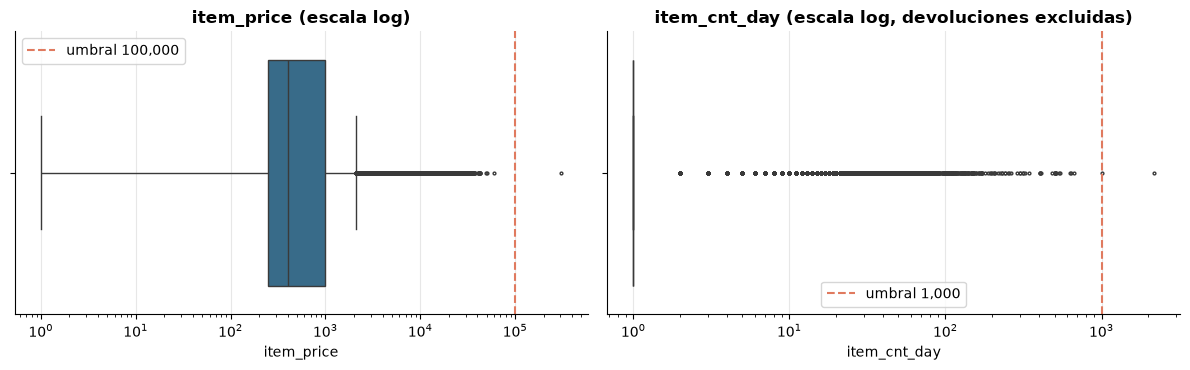

In [15]:
# Visualización de la cola de las distribuciones (escala log) con los umbrales elegidos
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.boxplot(x=sales_dt["item_price"].clip(lower=1), ax=axes[0], color=COLOR_MAIN, fliersize=2)
axes[0].set_xscale("log"); axes[0].axvline(MAX_ITEM_PRICE, color=COLOR_ACCENT, ls="--", label=f"umbral {MAX_ITEM_PRICE:,}")
axes[0].set_title("item_price (escala log)"); axes[0].legend()
sns.boxplot(x=sales_dt["item_cnt_day"].clip(lower=1), ax=axes[1], color=COLOR_MAIN, fliersize=2)
axes[1].set_xscale("log"); axes[1].axvline(MAX_ITEM_CNT_DAY, color=COLOR_ACCENT, ls="--", label=f"umbral {MAX_ITEM_CNT_DAY:,}")
axes[1].set_title("item_cnt_day (escala log, devoluciones excluidas)"); axes[1].legend()
plt.tight_layout(); save_fig(fig, "04b_outliers_precio_cantidad"); plt.show()

**Hallazgos y decisiones.**

| Caso | Filas | Diagnóstico | Decisión |
|---|---|---|---|
| `item_price = -1` | 1 | *DmC Devil May Cry (PS3)*, tienda 32, mayo 2013. Error de captura: el mismo producto en esa tienda y mes se vendió a 1,249 y 2,499 | **Imputar** con la mediana del mismo producto-tienda-mes (**1,874**); se conserva la unidad vendida |
| Devoluciones (`item_cnt_day < 0`) | 7,356 (0.25%) | Casi todas son −1. Representan 0.21% de las unidades. Más frecuentes en consolas y accesorios (≈0.5%) | **Conservar**: el objetivo mensual es la venta **neta**, y Kaggle trabaja así. Se agrega el indicador `is_return` |
| `item_price = 307,980` | 1 | *Radmin 3 — 522 licencias*: venta corporativa única en la tienda online; el producto **no tiene otra venta y no está en test** | **Eliminar** (umbral `item_price > 100,000`) |
| `item_cnt_day = 2,169` | 1 | Servicio de envío *Boxberry* en la tienda online, con precio unitario 0.91 (lo normal son ≈155): un registro contable agregado, no 2,169 ventas reales. Es el doble de la siguiente cantidad más alta | **Eliminar** (umbral `item_cnt_day > 1,000`) |

- Los umbrales se eligieron mirando la cola: el segundo precio más alto es 59,200 y la segunda
  cantidad más alta es 1,000. Así **solo se eliminan los dos puntos aislados** y se conservan
  ventas legítimas grandes, como 669 entradas a *ИгроМир 2015* o 624 copias de *GTA V*.
- No se aplica *capping* general en esta etapa: los valores altos restantes son reales (lanzamientos,
  eventos). El recorte [0, 20] del objetivo mensual se aplicará en el modelado.

### 4c. Registros duplicados y tiendas repetidas

**Duplicados exactos**: filas idénticas en las 6 columnas (misma fecha, tienda, producto, precio y
cantidad).

In [16]:
dup_mask = sales_dt.duplicated(keep=False)
print(f"Filas involucradas en duplicados: {dup_mask.sum()} | filas sobrantes a eliminar: {sales_dt.duplicated().sum()}")
display(sales_dt[dup_mask].merge(items_full[["item_id", "item_name"]], on="item_id").sort_values(["date", "shop_id"]))

# Duplicados en los catálogos
print("item_id repetidos en items.csv:", items.item_id.duplicated().sum())
print("Nombres de producto repetidos en items.csv:", items.item_name.duplicated().sum())
print("shop_id repetidos en shops.csv:", shops.shop_id.duplicated().sum())

Filas involucradas en duplicados: 12 | filas sobrantes a eliminar: 6


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,item_name
0,2013-01-05,0,54,20130,149.00,1.00,УЧЕНИК ЧАРОДЕЯ (регион)
1,2013-01-05,0,54,20130,149.00,1.00,УЧЕНИК ЧАРОДЕЯ (регион)
2,2014-02-23,13,50,3423,999.00,1.00,"Far Cry 3 (Classics) [Xbox 360, русская версия]"
3,2014-02-23,13,50,3423,999.00,1.00,"Far Cry 3 (Classics) [Xbox 360, русская версия]"
4,2014-03-23,14,21,3423,999.00,1.00,"Far Cry 3 (Classics) [Xbox 360, русская версия]"
5,2014-03-23,14,21,3423,999.00,1.00,"Far Cry 3 (Classics) [Xbox 360, русская версия]"
6,2014-05-01,16,50,3423,999.00,1.00,"Far Cry 3 (Classics) [Xbox 360, русская версия]"
7,2014-05-01,16,50,3423,999.00,1.00,"Far Cry 3 (Classics) [Xbox 360, русская версия]"
8,2014-07-12,18,25,3423,999.00,1.00,"Far Cry 3 (Classics) [Xbox 360, русская версия]"
9,2014-07-12,18,25,3423,999.00,1.00,"Far Cry 3 (Classics) [Xbox 360, русская версия]"


item_id repetidos en items.csv: 0
Nombres de producto repetidos en items.csv: 0
shop_id repetidos en shops.csv: 0


**Tiendas repetidas en `shops.csv`.** Los IDs son únicos, pero varios nombres son casi idénticos.
Se normaliza el nombre (minúsculas, sin signos ni la palabra "фран" = *franquicia*) para encontrar
candidatos y luego se verifica con la **actividad mensual**: si dos IDs son la misma tienda, nunca
deberían vender en el mismo mes.

In [17]:
import re

def normalize_shop(name: str) -> str:
    name = name.lower().replace("фран", "")
    return re.sub(r"[^a-zа-я0-9]", "", name)

shops_norm = shops.assign(norm=shops.shop_name.map(normalize_shop))
dup_names = shops_norm[shops_norm.norm.duplicated(keep=False)].sort_values("norm")
display(dup_names[["shop_id", "shop_name"]])

# Candidatos adicionales con nombre parecido (misma ciudad + mismo centro comercial)
display(shops[shops.shop_id.isin([39, 40, 23, 24])])

,shop_id,shop_name
10,10,Жуковский ул. Чкалова 39м?
11,11,Жуковский ул. Чкалова 39м²
0,0,"!Якутск Орджоникидзе, 56 фран"
57,57,"Якутск Орджоникидзе, 56"
1,1,"!Якутск ТЦ ""Центральный"" фран"
58,58,"Якутск ТЦ ""Центральный"""


,shop_name,shop_id
23,"Москва ТК ""Буденовский"" (пав.А2)",23
24,"Москва ТК ""Буденовский"" (пав.К7)",24
39,"РостовНаДону ТРК ""Мегацентр Горизонт""",39
40,"РостовНаДону ТРК ""Мегацентр Горизонт"" Островной",40


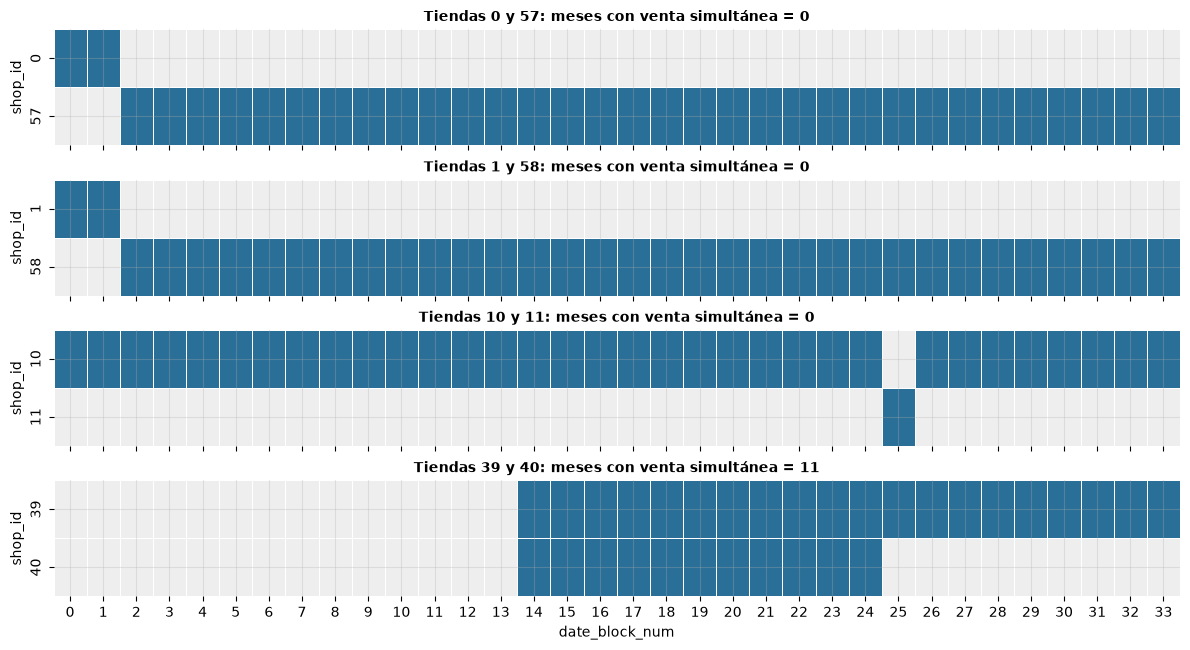

¿Aparecen en test? {0: False, 1: False, 10: True, 11: False, 39: True, 40: False, 57: True, 58: True}


In [18]:
# Actividad mensual (unidades) de cada pareja candidata
activity = sales_dt.pivot_table(index="shop_id", columns="date_block_num", values="item_cnt_day",
                                aggfunc="sum", fill_value=0)
pairs = [(0, 57), (1, 58), (10, 11), (39, 40)]

fig, axes = plt.subplots(len(pairs), 1, figsize=(12, 1.4 * len(pairs) + 1), sharex=True)
for ax, (a, b) in zip(axes, pairs):
    sns.heatmap((activity.loc[[a, b]] > 0).astype(int), ax=ax, cbar=False, cmap=["#eeeeee", COLOR_MAIN],
                linewidths=.5, linecolor="white")
    overlap = ((activity.loc[a] > 0) & (activity.loc[b] > 0)).sum()
    ax.set_title(f"Tiendas {a} y {b}: meses con venta simultánea = {overlap}", fontsize=10)
    ax.set_ylabel("shop_id"); ax.set_xlabel("")
axes[-1].set_xlabel("date_block_num")
plt.tight_layout(); save_fig(fig, "04c_tiendas_duplicadas"); plt.show()

print("¿Aparecen en test?", {s: s in set(test.shop_id) for s in [0, 1, 10, 11, 39, 40, 57, 58]})

**Duplicados exactos.** Hay 6 filas sobrantes (12 involucradas), todas de 1 unidad, mismo precio y
mismo día. Representan el 0.0002% de los datos. No hay identificador de ticket para distinguir dos
ventas reales de un doble registro. Dado que son exactas en todas las columnas y la cadena registra
ventas del mismo día y producto en **una** fila (sumando `item_cnt_day`), lo más probable es un
**doble registro**. **Decisión: eliminarlos.** El impacto en cualquier agregado es despreciable.
Los catálogos no tienen IDs ni nombres repetidos.

**Tiendas repetidas en `shops.csv`.**

| Pareja | Evidencia | Decisión |
|---|---|---|
| **0 → 57** (Yakutsk, Orjonikidze 56) | Mismo nombre (0 lleva "фран" = franquicia). La 0 vende solo en ene–feb 2013 y la 57 empieza en mar 2013: **0 meses simultáneos** | Unificar en **57** |
| **1 → 58** (Yakutsk, TC Tsentralni) | Mismo patrón exacto que 0/57 | Unificar en **58** |
| **11 → 10** (Zhukovski, Chkalova 39m²) | Nombre idéntico salvo un carácter mal codificado (`?` vs `²`). La 11 vende **solo en el mes 25**, justo el único mes en que la 10 no vende | Unificar en **10** |
| 39 / 40 (Rostov, Megacentr Gorizont) | La 40 es el pabellón "Ostrovnoi" del mismo centro comercial, pero **vendieron a la vez durante 11 meses** | **Mantener separadas** (son dos puntos de venta) |
| 23 / 24 (Moscú, TK Budenovski) | Pabellones distintos (A2 y K7) que vendieron simultáneamente | Mantener separadas |

Se mapea siempre al ID que **aparece en test.csv** (57, 58, 10), para que el historial de la tienda
antigua sirva para predecir. Con esto quedan **57 tiendas** distintas.

### 4d. Aplicación de la limpieza

Se aplican, en orden, las decisiones justificadas arriba. Cada paso imprime cuántas filas afecta.
Al final se comprueba que la función `clean_sales()` del paquete (la que usarán las etapas
siguientes) produce **exactamente** el mismo resultado.

In [19]:
df = sales_dt.copy()
log = []

# Paso 1: eliminar duplicados exactos
n0 = len(df); df = df.drop_duplicates().reset_index(drop=True)
log.append(("Eliminar duplicados exactos", n0 - len(df), "filas eliminadas"))

# Paso 2: imputar precio <= 0 con la mediana del mismo producto-tienda-mes
bad = df["item_price"] <= 0
for idx in df.index[bad]:
    same = df[(df.item_id == df.at[idx, "item_id"]) & (df.shop_id == df.at[idx, "shop_id"])
              & (df.date_block_num == df.at[idx, "date_block_num"]) & (df.item_price > 0)]
    df.at[idx, "item_price"] = same["item_price"].median()
log.append(("Imputar precio <= 0 (mediana producto-tienda-mes)", int(bad.sum()), "filas imputadas"))

# Paso 3: eliminar transacciones extremas puntuales
extreme = (df["item_price"] > MAX_ITEM_PRICE) | (df["item_cnt_day"] > MAX_ITEM_CNT_DAY)
df = df[~extreme].reset_index(drop=True)
log.append((f"Eliminar precio > {MAX_ITEM_PRICE:,} o cantidad > {MAX_ITEM_CNT_DAY:,}", int(extreme.sum()), "filas eliminadas"))

# Paso 4: unificar tiendas duplicadas (ID antiguo -> ID vigente que aparece en test)
n_remap = df["shop_id"].isin(SHOP_DUPLICATES.keys()).sum()
df["shop_id"] = df["shop_id"].replace(SHOP_DUPLICATES)
log.append((f"Unificar tiendas {SHOP_DUPLICATES}", int(n_remap), "filas reasignadas"))

# Las devoluciones se conservan (la venta mensual objetivo es neta)
log.append(("Conservar devoluciones (item_cnt_day < 0)", int((df.item_cnt_day < 0).sum()), "filas conservadas"))

display(pd.DataFrame(log, columns=["paso", "filas", "efecto"]))
print(f"Filas: {len(sales_raw):,} -> {len(df):,}")

# Verificación: la función del paquete reproduce exactamente la limpieza del notebook
pd.testing.assert_frame_equal(df, clean_sales(sales_raw))
print("OK: clean_sales() del paquete == limpieza paso a paso del notebook")

,paso,filas,efecto
0,Eliminar duplicados exactos,6,filas eliminadas
1,Imputar precio <= 0 (mediana producto-tienda-mes),1,filas imputadas
2,"Eliminar precio > 100,000 o cantidad > 1,000",2,filas eliminadas
3,"Unificar tiendas {0: 57, 1: 58, 11: 10}",16034,filas reasignadas
4,Conservar devoluciones (item_cnt_day < 0),7356,filas conservadas


Filas: 2,935,849 -> 2,935,841


OK: clean_sales() del paquete == limpieza paso a paso del notebook


Finalmente se enriquecen las ventas limpias con los catálogos y columnas derivadas
(`add_catalog_info`): año, mes, día de la semana, **ingreso** (`revenue = item_price × item_cnt_day`),
indicador de devolución, categoría (ES), grupo de categoría, ciudad y tipo de tienda. El resultado se
guarda en `data/interim/` para no repetir la limpieza.

In [20]:
sales = add_catalog_info(df, items_full, shops_full)
assert sales.isna().sum().sum() == 0, "Hay nulos tras unir los catálogos"
display(sales.head())
print(sales.shape)

sales.to_csv(INTERIM_DATA_DIR / "sales_clean_enriched.csv", index=False)
print("Guardado en", INTERIM_DATA_DIR / "sales_clean_enriched.csv")

,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,year,month,day_of_week,revenue,is_return,item_category_id,category_es,category_group,city,shop_type,shop_label
0,2013-01-02,0,59,22154,999.00,1.00,2013,1,2,999.00,False,37,Cine - Blu-Ray,Cine,Yaroslavl,Centro comercial,59 · Yaroslavl
1,2013-01-03,0,25,2552,899.00,1.00,2013,1,3,899.00,False,58,Música - Vinilo,Música,Moscú,Centro comercial,25 · Moscú
2,2013-01-05,0,25,2552,899.00,-1.00,2013,1,5,-899.00,True,58,Música - Vinilo,Música,Moscú,Centro comercial,25 · Moscú
3,2013-01-06,0,25,2554,"1,709.05",1.00,2013,1,6,"1,709.05",False,58,Música - Vinilo,Música,Moscú,Centro comercial,25 · Moscú
4,2013-01-15,0,25,2555,"1,099.00",1.00,2013,1,1,"1,099.00",False,56,Música - CD producción de marca,Música,Moscú,Centro comercial,25 · Moscú


(2935841, 17)


Guardado en C:\Users\cesar\OneDrive\Escritorio\maestria\Segundo año\Cuarto trimeste\Product Development\proyecto1\Predict Future Sales\data\interim\sales_clean_enriched.csv


## 5. Análisis descriptivo general

### 5a. Métricas estadísticas básicas

Media, mediana, mínimo, máximo y desviación estándar de `item_price`, `item_cnt_day` y `revenue`,
a nivel **transacción** (fila diaria) y, para el objetivo, a nivel **par-mes**. Se agrega la
asimetría (*skewness*) porque la diferencia media–mediana anticipa colas largas.

In [21]:
def describe_basic(s: pd.Series) -> pd.Series:
    return pd.Series({"media": s.mean(), "mediana": s.median(), "mínimo": s.min(), "máximo": s.max(),
                      "desv_std": s.std(), "asimetría": s.skew(), "n": len(s)})

monthly_pairs = (sales.groupby(["date_block_num", "shop_id", "item_id"], as_index=False)
                 .agg(item_cnt_month=("item_cnt_day", "sum"), revenue_month=("revenue", "sum")))

stats = pd.DataFrame({
    "item_price": describe_basic(sales["item_price"]),
    "item_cnt_day": describe_basic(sales["item_cnt_day"]),
    "revenue (por transacción)": describe_basic(sales["revenue"]),
    "item_cnt_month (por par-mes)": describe_basic(monthly_pairs["item_cnt_month"]),
    "revenue (por par-mes)": describe_basic(monthly_pairs["revenue_month"]),
}).T
display(stats.style.format({c: ("{:,.0f}" if c == "n" else "{:,.2f}") for c in stats.columns}))

,media,mediana,mínimo,máximo,desv_std,asimetría,n
item_price,890.75,399.00,0.07,"59,200.00","1,720.49",8.99,"2,935,841"
item_cnt_day,1.24,1.00,-22.00,"1,000.00",2.29,118.66,"2,935,841"
revenue (por transacción),"1,157.63",449.00,"-68,970.00","1,829,990.00","5,680.79",103.66,"2,935,841"
item_cnt_month (por par-mes),2.27,1.00,-22.00,"1,644.00",8.47,62.35,"1,609,123"
revenue (por par-mes),"2,112.09",537.00,"-33,787.00","6,264,230.00","15,314.56",110.28,"1,609,123"


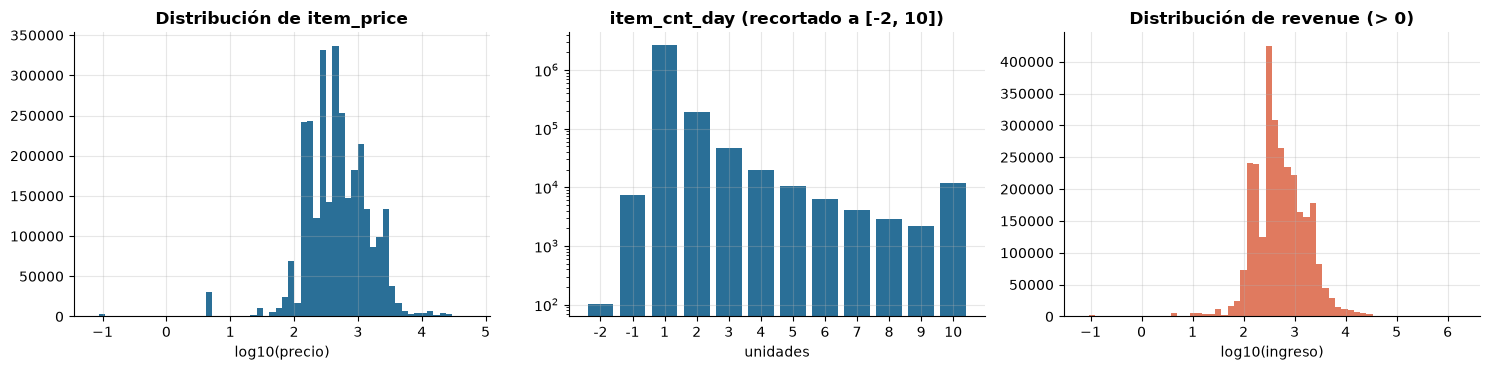

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(np.log10(sales["item_price"]), bins=60, color=COLOR_MAIN)
axes[0].set_title("Distribución de item_price"); axes[0].set_xlabel("log10(precio)")
vc = sales["item_cnt_day"].clip(-2, 10).value_counts().sort_index()
axes[1].bar(vc.index.astype(int).astype(str), vc.values, color=COLOR_MAIN)
axes[1].set_yscale("log"); axes[1].set_title("item_cnt_day (recortado a [-2, 10])"); axes[1].set_xlabel("unidades")
axes[2].hist(np.log10(sales.loc[sales.revenue > 0, "revenue"]), bins=60, color=COLOR_ACCENT)
axes[2].set_title("Distribución de revenue (> 0)"); axes[2].set_xlabel("log10(ingreso)")
plt.tight_layout(); save_fig(fig, "05a_distribuciones"); plt.show()

**Interpretación.**

- **`item_price`**: media 891 vs mediana 399 rublos y asimetría ≈ 9: distribución muy sesgada a la
  derecha. La mayoría de los productos son baratos (DVD, CD, juegos de PC) y unos pocos (consolas)
  son muy caros. En escala logarítmica la distribución es aproximadamente unimodal.
- **`item_cnt_day`**: mediana 1 y media 1.24. **El 90% de las transacciones son de exactamente 1
  unidad**; la asimetría (≈119) la causan pocos registros masivos de la tienda online.
- **Ingreso por transacción**: media 1,158 vs mediana 449 rublos; sigue la forma del precio.
- **Objetivo mensual (par-mes)**: mediana 1 y media 2.27, con una cola muy larga (máximo 1,644).

**Implicación:** las métricas basadas en la media y el RMSE serán sensibles a la cola. Para modelar,
conviene recortar el objetivo a [0, 20] y usar transformaciones logarítmicas en precio e ingreso.

### 5b-i. Distribución de ventas por producto y categoría

Primero se mide la **concentración**: ¿qué proporción de las unidades explican los productos más
vendidos? (curva de Pareto). Luego se resume por grupo de categoría.

Productos con ventas: 21,806
  El top 1% de productos (218) concentra el 28.1% de las unidades
  El top 5% de productos (1,090) concentra el 53.3% de las unidades
  El top 20% de productos (4,361) concentra el 82.4% de las unidades
  Productos con <= 10 unidades en todo el histórico: 30.8%
  Producto #1 (item 20949) = 5.1% de todas las unidades


,count,mean,std,min,25%,50%,75%,90%,99%,max
unidades por producto,"21,806.00",167.20,"1,365.86",-11.00,7.00,33.00,124.00,360.00,"1,991.80","187,642.00"


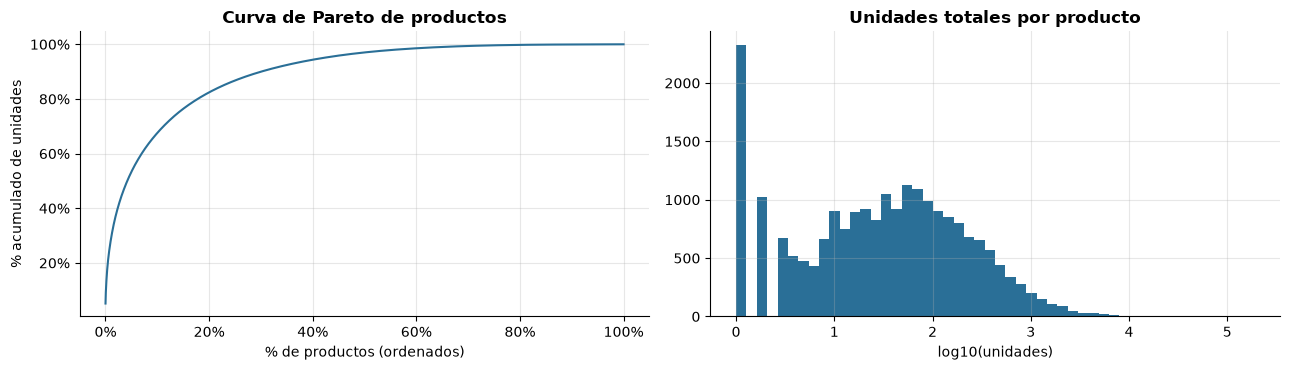

In [23]:
item_tot = (sales.groupby("item_id").agg(units=("item_cnt_day", "sum"), revenue=("revenue", "sum"),
                                          months=("date_block_num", "nunique"))
            .sort_values("units", ascending=False))
cum = item_tot["units"].cumsum() / item_tot["units"].sum()

print(f"Productos con ventas: {len(item_tot):,}")
for p in [0.01, 0.05, 0.20]:
    k = int(len(item_tot) * p)
    print(f"  El top {p:.0%} de productos ({k:,}) concentra el {cum.iloc[k - 1]:.1%} de las unidades")
print(f"  Productos con <= 10 unidades en todo el histórico: {(item_tot.units <= 10).mean():.1%}")
print(f"  Producto #1 (item {item_tot.index[0]}) = {item_tot.units.iloc[0] / item_tot.units.sum():.1%} de todas las unidades")
display(item_tot["units"].describe(percentiles=[.25, .5, .75, .9, .99]).to_frame("unidades por producto").T)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(np.arange(1, len(cum) + 1) / len(cum), cum.values, color=COLOR_MAIN)
axes[0].set_title("Curva de Pareto de productos"); axes[0].set_xlabel("% de productos (ordenados)")
axes[0].set_ylabel("% acumulado de unidades"); axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
axes[1].hist(np.log10(item_tot.units.clip(lower=1)), bins=50, color=COLOR_MAIN)
axes[1].set_title("Unidades totales por producto"); axes[1].set_xlabel("log10(unidades)")
plt.tight_layout(); save_fig(fig, "05b_pareto_productos"); plt.show()

,unidades,ingreso,productos,precio_mediano,% unidades,% ingreso
category_group,,,,,,
Cine,"916,941","334,987,320","7,390",299,25.1%,9.9%
Juegos PC,"689,098","477,981,688","2,129",499,18.9%,14.1%
Juegos,"646,770","1,153,844,547","1,732","1,399",17.7%,34.0%
Regalos,"584,366","309,146,571","3,461",569,16.0%,9.1%
Música,"411,294","149,719,999","4,259",299,11.3%,4.4%
Accesorios,"85,056","166,386,781",217,"1,790",2.3%,4.9%
Libros,"76,341","30,348,897","1,229",299,2.1%,0.9%
Programas,"74,953","122,082,915","1,133","1,190",2.1%,3.6%
Tarjetas de pago,"53,883","72,953,096",41,"1,049",1.5%,2.1%


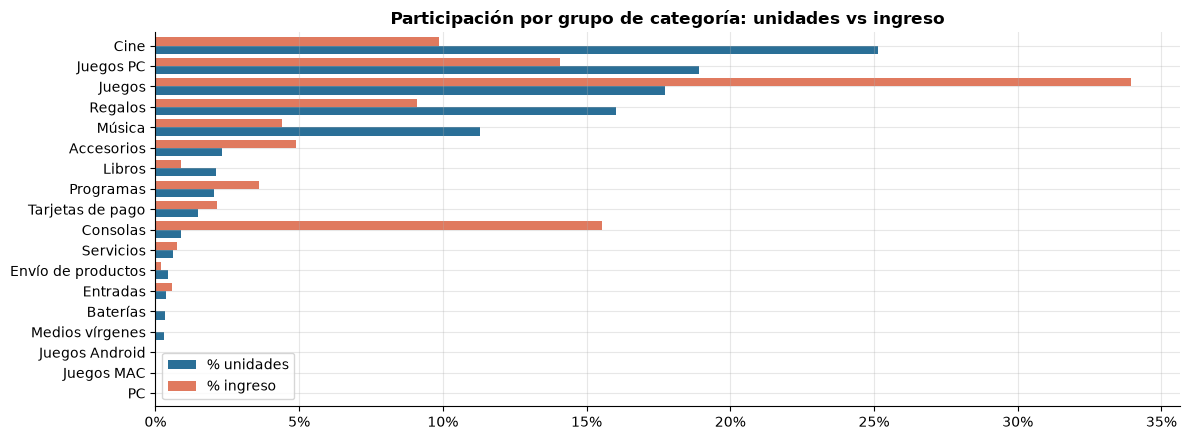

In [24]:
grp = (sales.groupby("category_group")
       .agg(unidades=("item_cnt_day", "sum"), ingreso=("revenue", "sum"),
            productos=("item_id", "nunique"), precio_mediano=("item_price", "median"))
       .sort_values("unidades", ascending=False))
grp["% unidades"] = grp.unidades / grp.unidades.sum()
grp["% ingreso"] = grp.ingreso / grp.ingreso.sum()
display(grp.style.format({"unidades": "{:,.0f}", "ingreso": "{:,.0f}", "productos": "{:,}",
                          "precio_mediano": "{:,.0f}", "% unidades": "{:.1%}", "% ingreso": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(12, 4.5))
g = grp[["% unidades", "% ingreso"]].iloc[::-1]
g.plot.barh(ax=ax, color=[COLOR_MAIN, COLOR_ACCENT], width=.8)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set_title("Participación por grupo de categoría: unidades vs ingreso"); ax.set_ylabel("")
plt.tight_layout(); save_fig(fig, "05b_grupos_categoria"); plt.show()

**Interpretación: producto.**

- **Alta concentración (efecto Pareto)**: el 20% de los productos genera el **82%** de las unidades y
  el 1% genera el 28%. En cambio, **31% de los productos vendió 10 unidades o menos** en casi 3 años
  (cola larga de catálogo).
- El producto #1 (item 20949, la **bolsa de compra con logo de 1C**) concentra por sí solo el 5.1%
  de las unidades. No es una mercancía, sino un indicador indirecto del número de compras en tienda.

**Interpretación: categoría.**

- **Cine (DVD/Blu-Ray) lidera en unidades (25%)**, pero solo aporta el 10% del ingreso (precio
  mediano 299).
- **Juegos de consola** son el motor del **ingreso (34%)** con solo el 18% de las unidades.
- **Consolas** son el caso extremo: 0.9% de las unidades pero **15.5% del ingreso** (precio mediano
  13,990).

**Implicación:** en unidades (lo que se predice) mandan Cine, Juegos PC, Juegos, Regalos y Música,
que suman el **89% de las unidades**. La categoría es una variable clave para el modelo.

### 5b-ii. Distribución de ventas por sucursal (tienda)

,count,mean,std,min,25%,50%,75%,max
unidades por tienda,57.00,"63,965.44","58,413.28",330.00,"25,838.00","53,886.00","71,201.00","310,777.00"


Top 5 tiendas = 29.5% de las unidades


,tiendas,unidades,ingreso,unidades_por_tienda
shop_type,,,,
Centro comercial,49,"3,150,970","2,915,878,244","64,306"
Calle,4,"338,626","298,075,436","84,656"
Online,2,"134,696","161,687,183","67,348"
Itinerante,1,"15,866","16,372,837","15,866"
Liquidación,1,"5,872","6,599,924","5,872"


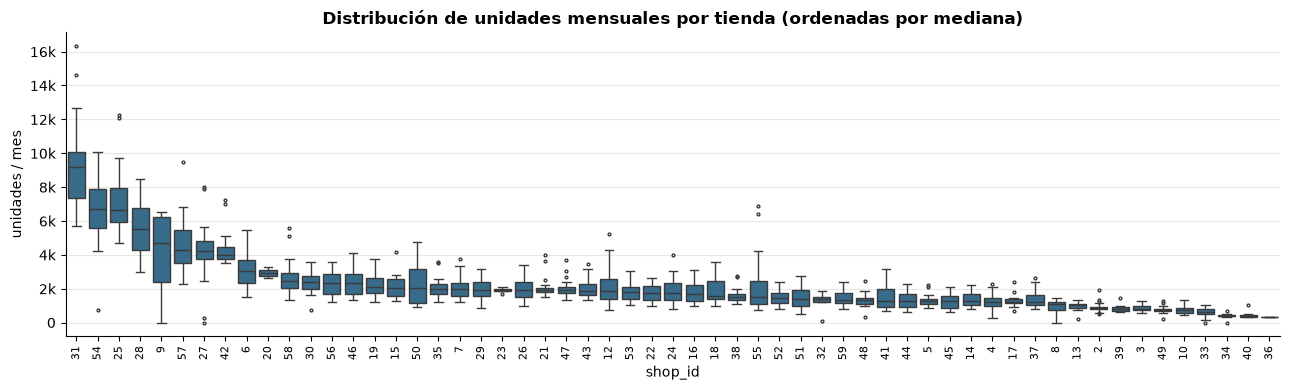

In [25]:
shop_month = sales.groupby(["shop_id", "date_block_num"])["item_cnt_day"].sum().rename("units").reset_index()
shop_tot = (sales.groupby(["shop_id", "shop_label", "shop_type"])
            .agg(unidades=("item_cnt_day", "sum"), ingreso=("revenue", "sum"))
            .reset_index().sort_values("unidades", ascending=False))
display(shop_tot["unidades"].describe().to_frame("unidades por tienda").T)
print(f"Top 5 tiendas = {shop_tot.unidades.head(5).sum() / shop_tot.unidades.sum():.1%} de las unidades")

by_type = (shop_tot.groupby("shop_type").agg(tiendas=("shop_id", "count"), unidades=("unidades", "sum"),
                                             ingreso=("ingreso", "sum")))
by_type["unidades_por_tienda"] = by_type.unidades / by_type.tiendas
display(by_type.sort_values("unidades", ascending=False).style.format("{:,.0f}"))

fig, ax = plt.subplots(figsize=(13, 4))
order = shop_month.groupby("shop_id")["units"].median().sort_values(ascending=False).index
sns.boxplot(data=shop_month, x="shop_id", y="units", order=order, ax=ax, color=COLOR_MAIN, fliersize=2)
ax.set_title("Distribución de unidades mensuales por tienda (ordenadas por mediana)")
ax.set_xlabel("shop_id"); ax.set_ylabel("unidades / mes"); ax.yaxis.set_major_formatter(thousands_formatter())
plt.xticks(rotation=90, fontsize=8); plt.tight_layout(); save_fig(fig, "05b_boxplot_tiendas"); plt.show()

**Interpretación.**

- Las ventas por tienda son **muy desiguales**: mediana de 53,886 unidades, pero las top 5 (tres de
  Moscú, más Jimki y Yakutsk) concentran el **29.5%**. La tienda 31 (Moscú) vende **5 veces la
  mediana**.
- La gran mayoría son tiendas en **centros comerciales** (49 de 57). Las de **calle** son pocas pero
  de alto volumen por tienda (84,656 unidades en promedio). Las **online** venden un volumen medio
  con precio alto, y la **itinerante** y la de **liquidación** son marginales.
- Los *boxplots* muestran que cada tienda tiene un nivel propio y una dispersión mensual amplia, con
  *outliers* altos (los diciembres). **El ID de tienda aporta un "nivel base" que el modelo debe
  capturar.**

### 5b-iii. Distribución de ventas por periodo (día, semana, mes, año)

Para comparar años de forma justa, 2015 solo tiene datos hasta octubre: se compara también el
acumulado **enero–octubre** de cada año.

,media,mediana,mínimo,máximo,desv_std
día,"3,526","3,144","1,274","13,343","1,586"
semana,"24,646","24,500","12,389","57,680","7,801"
mes,"107,236","107,306","63,187","183,341","28,542"


,unidades,ingreso,unidades_ene_oct,ingreso_ene_oct,var_unidades_ene_oct,var_ingreso_ene_oct
year,,,,,,
2013,"1,562,731","1,217,218,480","1,249,381","871,289,289",—,—
2014,"1,320,884","1,346,773,984","1,034,285","962,711,713",-17.2%,+10.5%
2015,"762,415","834,621,161","762,415","834,621,161",-26.3%,-13.3%


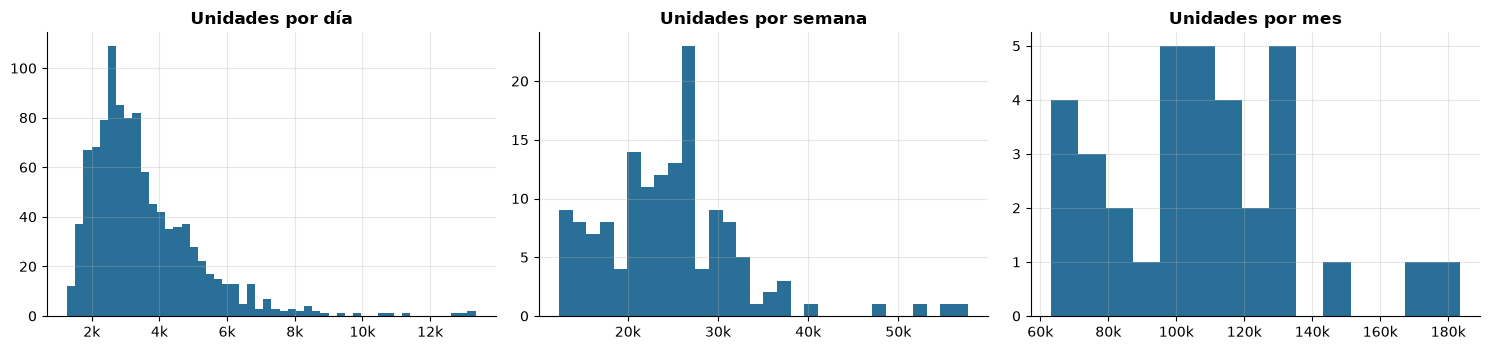

In [26]:
daily = sales.groupby("date").agg(units=("item_cnt_day", "sum"), revenue=("revenue", "sum"))
weekly = daily.resample("W-SUN").sum().iloc[1:-1]      # se descartan semanas incompletas en los extremos
monthly = sales.groupby("date_block_num").agg(units=("item_cnt_day", "sum"), revenue=("revenue", "sum"))
monthly.index = pd.date_range("2013-01-01", periods=len(monthly), freq="MS")

per = pd.DataFrame({
    "día": daily["units"].describe(), "semana": weekly["units"].describe(), "mes": monthly["units"].describe(),
}).T[["mean", "50%", "min", "max", "std"]]
per.columns = ["media", "mediana", "mínimo", "máximo", "desv_std"]
display(per.style.format("{:,.0f}"))

yearly = sales.groupby("year").agg(unidades=("item_cnt_day", "sum"), ingreso=("revenue", "sum"))
ytd = sales[sales.month <= 10].groupby("year").agg(unidades_ene_oct=("item_cnt_day", "sum"),
                                                   ingreso_ene_oct=("revenue", "sum"))
yearly = yearly.join(ytd)
yearly["var_unidades_ene_oct"] = yearly.unidades_ene_oct.pct_change()
yearly["var_ingreso_ene_oct"] = yearly.ingreso_ene_oct.pct_change()
display(yearly.style.format({c: "{:,.0f}" for c in yearly.columns[:4]} | {"var_unidades_ene_oct": "{:+.1%}", "var_ingreso_ene_oct": "{:+.1%}"}, na_rep="—"))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].hist(daily.units, bins=50, color=COLOR_MAIN); axes[0].set_title("Unidades por día")
axes[1].hist(weekly.units, bins=30, color=COLOR_MAIN); axes[1].set_title("Unidades por semana")
axes[2].hist(monthly.units, bins=15, color=COLOR_MAIN); axes[2].set_title("Unidades por mes")
for ax in axes: ax.xaxis.set_major_formatter(thousands_formatter())
plt.tight_layout(); save_fig(fig, "05b_distribucion_periodos"); plt.show()

**Interpretación.**

- **Día**: en promedio se venden 3,526 unidades por día, con rango de 1,274 a 13,343 (los máximos
  están en la última semana de diciembre).
- **Semana**: 24,646 unidades en promedio.
- **Mes**: 107,236 unidades en promedio, con rango de 63,187 a 183,341.
- **Año**: comparando el mismo periodo (enero–octubre):
  - las **unidades caen −17% en 2014 y −26% en 2015**;
  - el **ingreso sube +10.5% en 2014** y cae −13% en 2015.

Se venden menos unidades pero más caras: el mix se desplaza hacia productos de mayor precio
(consolas PS4/Xbox One a fines de 2013–2014) y el formato físico (DVD, CD) pierde peso. El negocio
está **en contracción en volumen**, un dato crítico para pronosticar noviembre 2015.

## 6. Exploración temporal

### 6a. Evolución de las ventas a lo largo del tiempo

La misma serie en tres granularidades: la diaria muestra el ruido y los picos puntuales, la semanal
suaviza el ciclo semanal y la mensual (la del objetivo) muestra tendencia y estacionalidad.

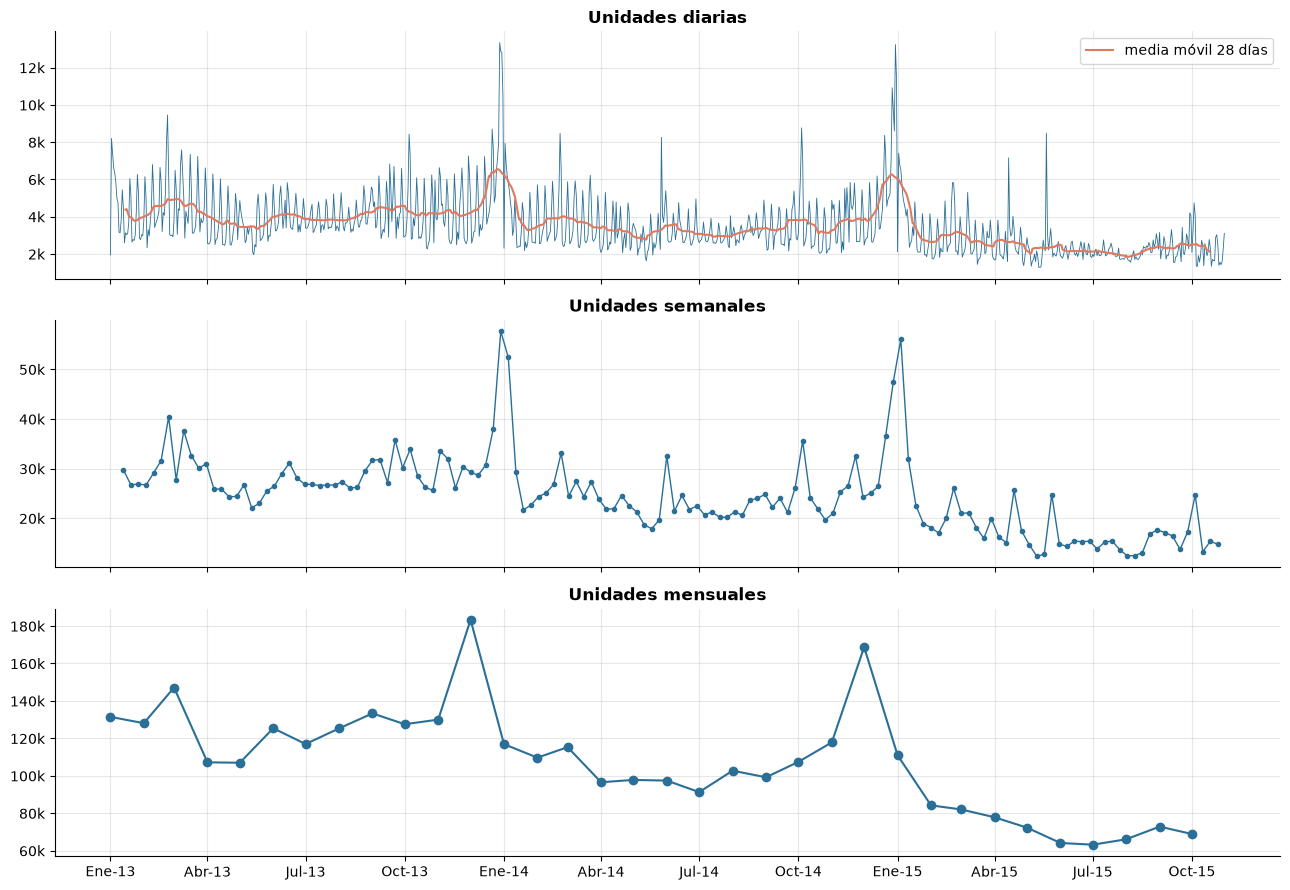

In [27]:
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
axes[0].plot(daily.index, daily.units, color=COLOR_MAIN, lw=.6)
axes[0].plot(daily.index, daily.units.rolling(28, center=True).mean(), color=COLOR_ACCENT, lw=1.5, label="media móvil 28 días")
axes[0].set_title("Unidades diarias"); axes[0].legend(loc="upper right")
axes[1].plot(weekly.index, weekly.units, color=COLOR_MAIN, marker=".", lw=1)
axes[1].set_title("Unidades semanales")
axes[2].plot(monthly.index, monthly.units, color=COLOR_MAIN, marker="o")
axes[2].set_title("Unidades mensuales")
for ax in axes: ax.yaxis.set_major_formatter(thousands_formatter())
axes[2].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
axes[2].xaxis.set_major_formatter(date_formatter_es())
plt.tight_layout(); save_fig(fig, "06a_evolucion_ventas"); plt.show()

### 6b-i. Tendencia

Se ajusta una recta (mínimos cuadrados) sobre las unidades mensuales y se calcula la media móvil
de 12 meses, que elimina la estacionalidad anual y deja solo la tendencia.

Tendencia lineal unidades: -1,954 unidades/mes (-1.82% de la media por mes)
Tendencia lineal ingreso:  -79,573 rublos/mes (-0.08% de la media por mes)


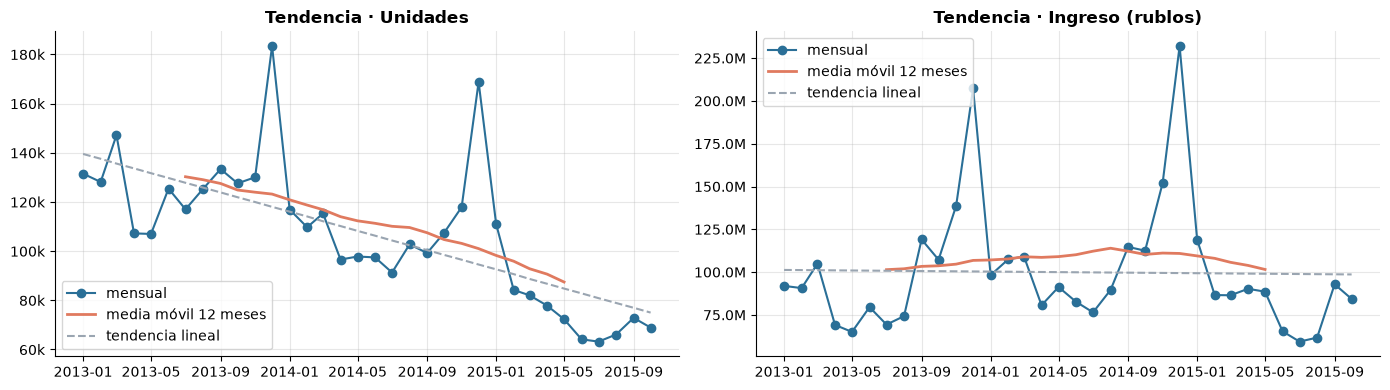

In [28]:
t_idx = np.arange(len(monthly))
slope_u, intercept_u = np.polyfit(t_idx, monthly.units, 1)
slope_r, intercept_r = np.polyfit(t_idx, monthly.revenue, 1)
print(f"Tendencia lineal unidades: {slope_u:,.0f} unidades/mes ({slope_u / monthly.units.mean():+.2%} de la media por mes)")
print(f"Tendencia lineal ingreso:  {slope_r:,.0f} rublos/mes ({slope_r / monthly.revenue.mean():+.2%} de la media por mes)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col, slope, inter, title in [(axes[0], "units", slope_u, intercept_u, "Unidades"),
                                     (axes[1], "revenue", slope_r, intercept_r, "Ingreso (rublos)")]:
    ax.plot(monthly.index, monthly[col], color=COLOR_MAIN, marker="o", label="mensual")
    ax.plot(monthly.index, monthly[col].rolling(12, center=True).mean(), color=COLOR_ACCENT, lw=2, label="media móvil 12 meses")
    ax.plot(monthly.index, inter + slope * t_idx, color=COLOR_MUTED, ls="--", label="tendencia lineal")
    ax.set_title(f"Tendencia · {title}"); ax.yaxis.set_major_formatter(thousands_formatter()); ax.legend()
plt.tight_layout(); save_fig(fig, "06b_tendencia"); plt.show()

In [29]:
# ¿La caída en unidades es por menos tiendas activas o por menos ventas por tienda?
active = sales.groupby("date_block_num").agg(tiendas_activas=("shop_id", "nunique"),
                                             productos_activos=("item_id", "nunique"),
                                             unidades=("item_cnt_day", "sum"),
                                             ingreso=("revenue", "sum"))
active["unidades_por_tienda"] = active.unidades / active.tiendas_activas
active["precio_medio_ponderado"] = active.ingreso / active.unidades
display(active.iloc[[0, 11, 12, 23, 24, 33]].style.format("{:,.0f}"))

,tiendas_activas,productos_activos,unidades,ingreso,unidades_por_tienda,precio_medio_ponderado
date_block_num,,,,,,
0,45,"8,115","131,478","91,946,942","2,922",699
11,46,"8,473","183,341","207,263,751","3,986","1,130"
12,46,"7,551","116,899","98,226,023","2,541",840
23,50,"6,605","168,754","232,024,672","3,375","1,375"
24,50,"6,139","110,971","118,927,700","2,219","1,072"
33,44,"5,413","68,887","84,335,142","1,566","1,224"


**Interpretación: tendencia.**

- La media móvil de 12 meses y la descomposición muestran una **tendencia decreciente clara en
  unidades**: aproximadamente **−1,950 unidades por mes**, es decir −1.8% de la media cada mes.
- **El ingreso es casi plano** (−0.08% por mes): la caída de volumen se compensa con un precio medio
  ponderado que sube de ≈700 a ≈1,200 rublos.
- La caída **no se explica por cierre de tiendas**: el número de tiendas activas se mantiene entre
  44 y 50. Lo que cae es la **venta por tienda** (de ≈2,900 a ≈1,570 unidades/mes) y el número de
  **productos activos** (de 8,115 a 5,413 por mes).

**Implicación para forecasting:** un modelo que no capture la tendencia (por ejemplo, un promedio
histórico simple) **sobreestimará** noviembre 2015. Los rezagos recientes (último mes, últimos 3
meses) pesan más que el historial lejano.

### 6b-ii. Estacionalidad

Descomposición aditiva clásica de la serie mensual con periodo 12 (`seasonal_decompose`): serie =
tendencia + estacionalidad + residuo. Con 34 meses hay casi 3 ciclos anuales, suficiente para
estimar el componente estacional.

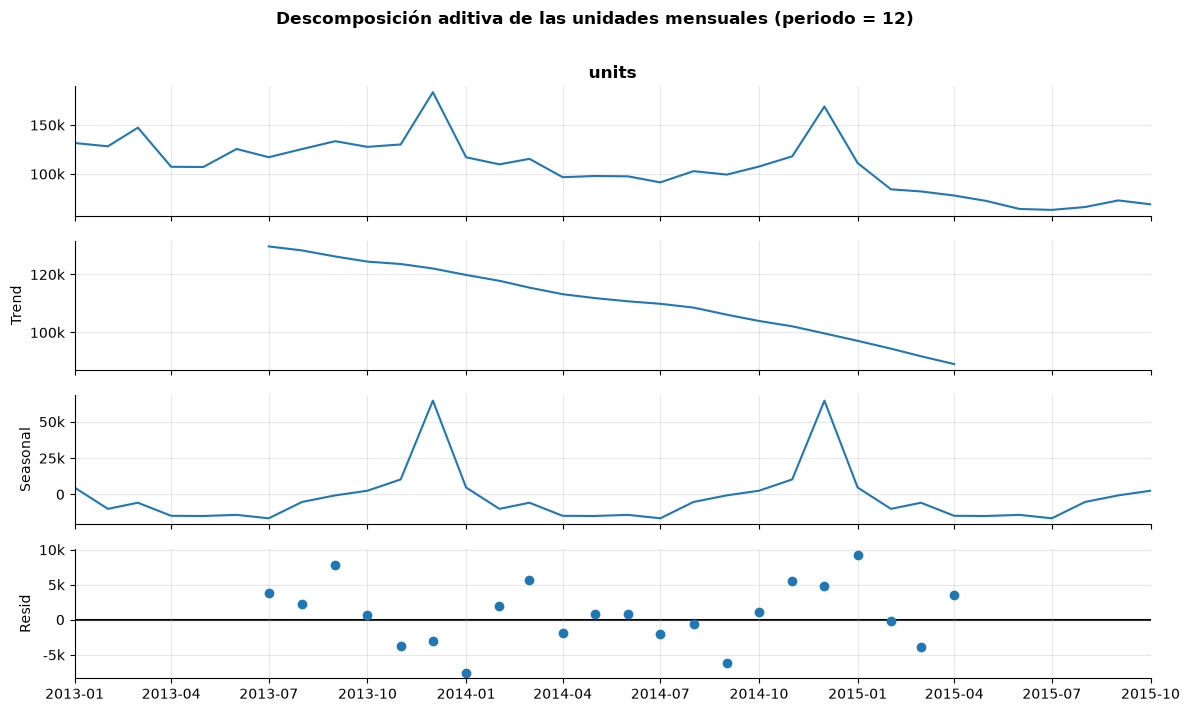

mes,1,2,3,4,5,6,7,8,9,10,11,12
efecto_estacional_unidades,"+4,671","-9,968","-5,762","-14,743","-14,859","-14,105","-16,453","-5,228",-693,"+2,487","+10,267","+64,386"
% sobre la media,+4.4%,-9.3%,-5.4%,-13.7%,-13.9%,-13.2%,-15.3%,-4.9%,-0.6%,+2.3%,+9.6%,+60.0%


In [30]:
decomp = seasonal_decompose(monthly["units"], model="additive", period=12)
fig = decomp.plot(); fig.set_size_inches(12, 7)
for ax in fig.axes: ax.yaxis.set_major_formatter(thousands_formatter())
fig.suptitle("Descomposición aditiva de las unidades mensuales (periodo = 12)", y=1.01, fontweight="bold")
plt.tight_layout(); save_fig(fig, "06b_descomposicion"); plt.show()

seasonal_idx = decomp.seasonal.groupby(decomp.seasonal.index.month).first()
seasonal_pct = seasonal_idx / monthly.units.mean()
display(pd.DataFrame({"efecto_estacional_unidades": seasonal_idx, "% sobre la media": seasonal_pct})
        .rename_axis("mes").T.style.format("{:+,.0f}").format("{:+.1%}", subset=pd.IndexSlice["% sobre la media", :]))

**Interpretación: estacionalidad.**

- Hay una **estacionalidad anual fuerte y dominada por diciembre**: el efecto estacional de
  diciembre es **+60% sobre la media mensual** (temporada navideña y de Año Nuevo, la principal fecha
  de regalos en Rusia).
- **Noviembre**, el mes a predecir, también está **por encima de la media (+9.6%)**: es la antesala
  de diciembre.
- Los meses de **abril a julio** son los más bajos (−13% a −15%), y enero todavía arrastra algo de
  la temporada (+4%).
- El residuo es pequeño (±10k) comparado con el componente estacional (+64k en diciembre): la
  descomposición tendencia + estacionalidad explica la mayor parte de la serie.

### 6b-iii. Picos o caídas abruptas

Se identifican los días y meses más extremos, y los cambios mensuales más fuertes (variación %
contra el mes anterior).

In [31]:
print("Top 8 días con más unidades:")
display(daily.nlargest(8, "units").assign(dia=lambda x: x.index.day_name()).style.format({"units": "{:,.0f}", "revenue": "{:,.0f}"}))
print("8 días con menos unidades:")
display(daily.nsmallest(8, "units").assign(dia=lambda x: x.index.day_name()).style.format({"units": "{:,.0f}", "revenue": "{:,.0f}"}))

mom = monthly.assign(var_unidades=monthly.units.pct_change(), var_ingreso=monthly.revenue.pct_change())
print("Cambios mensuales más fuertes (vs mes anterior):")
display(mom.reindex(mom.var_unidades.abs().sort_values(ascending=False).index).head(8)
        .style.format({"units": "{:,.0f}", "revenue": "{:,.0f}", "var_unidades": "{:+.1%}", "var_ingreso": "{:+.1%}"}))

Top 8 días con más unidades:


,units,revenue,dia
date,,,
2013-12-28 00:00:00,"13,343","14,626,701",Saturday
2014-12-30 00:00:00,"13,236","17,002,645",Tuesday
2013-12-29 00:00:00,"12,863","14,273,758",Sunday
2013-12-30 00:00:00,"12,823","14,671,056",Monday
2014-12-31 00:00:00,"11,393","15,021,005",Wednesday
2014-12-27 00:00:00,"10,919","15,649,898",Saturday
2013-12-31 00:00:00,"10,514","12,115,056",Tuesday
2014-12-28 00:00:00,"9,727","12,455,894",Sunday


8 días con menos unidades:


,units,revenue,dia
date,,,
2015-05-12 00:00:00,"1,274","1,350,036",Tuesday
2015-05-13 00:00:00,"1,294","1,244,734",Wednesday
2015-05-14 00:00:00,"1,302","1,239,649",Thursday
2015-10-05 00:00:00,"1,340","1,639,809",Monday
2015-10-19 00:00:00,"1,341","1,266,478",Monday
2015-10-06 00:00:00,"1,343","1,339,565",Tuesday
2015-05-05 00:00:00,"1,349","1,226,029",Tuesday
2015-10-12 00:00:00,"1,363","1,585,838",Monday


Cambios mensuales más fuertes (vs mes anterior):


,units,revenue,var_unidades,var_ingreso
2014-12-01 00:00:00,"168,754","232,024,672",+43.2%,+52.6%
2013-12-01 00:00:00,"183,341","207,263,751",+41.0%,+49.5%
2014-01-01 00:00:00,"116,899","98,226,023",-36.2%,-52.6%
2015-01-01 00:00:00,"110,971","118,927,700",-34.2%,-48.7%
2013-04-01 00:00:00,"107,190","69,154,286",-27.2%,-34.1%
2015-02-01 00:00:00,"84,198","86,593,884",-24.1%,-27.2%
2013-06-01 00:00:00,"125,381","79,550,406",+17.2%,+22.3%
2014-04-01 00:00:00,"96,556","80,651,755",-16.3%,-26.1%


In [32]:
# Los picos de ingreso que no coinciden con picos de unidades suelen ser lanzamientos de productos caros
peak_months = mom.var_ingreso.nlargest(4).index
for m in peak_months:
    blk = (m.year - 2013) * 12 + m.month - 1
    top = (sales[sales.date_block_num == blk].groupby("item_id")["revenue"].sum().nlargest(1))
    it_id = top.index[0]
    print(f"{m:%b-%Y}: ingreso {mom.loc[m, 'var_ingreso']:+.1%} vs mes previo | producto con más ingreso: "
          f"{it_id} '{items_full.set_index('item_id').at[it_id, 'item_name'][:45]}' "
          f"({top.iloc[0] / mom.loc[m, 'revenue']:.1%} del ingreso del mes)")

Sep-2013: ingreso +60.3% vs mes previo | producto con más ingreso: 3732 'Grand Theft Auto V [PS3, русские субтитры]' (14.9% del ingreso del mes)
Dec-2014: ingreso +52.6% vs mes previo | producto con más ingreso: 13443 'Комплект Sony PS4 (500 Gb) Black (CUH-1108A/B' (10.4% del ingreso del mes)
Sep-2015: ingreso +50.5% vs mes previo | producto con más ingreso: 3351 'FIFA 16 [PS4, русская версия]' (6.3% del ingreso del mes)
Dec-2013: ingreso +49.5% vs mes previo | producto con más ingreso: 6675 'Sony PlayStation 4 (500 Gb) Black (CUH-1008A/' (22.4% del ingreso del mes)


**Interpretación: picos y caídas.**

- **Los 8 días con más ventas son todos del 27 al 31 de diciembre** (2013 y 2014), con más de
  10,000 unidades diarias, unas 3 veces el promedio.
- **Los días más bajos son de 2015** (mayo y octubre). Esto es coherente con la tendencia
  decreciente y con los feriados de mayo en Rusia.
- **Cambios mensuales abruptos**:
  - diciembre sube **+41% a +43%** sobre noviembre;
  - enero cae **−34% a −36%**;
  - la caída de abril 2013 (−27%) sigue a un marzo 2013 alto, que **probablemente** se relaciona
    con el 8 de marzo (Día de la Mujer, fecha de regalos en Rusia).
- **Picos de ingreso explicados por lanzamientos**:
  - sep-2013: *GTA V* (15% del ingreso del mes);
  - dic-2013: la consola **PS4** (22% del ingreso del mes);
  - dic-2014: un *bundle* de PS4;
  - sep-2015: *FIFA 16*.

  **Los lanzamientos de productos estrella generan picos que no son estacionales.**

### 6b-iv. Ciclos por día de la semana y por mes del año

- **Día de la semana**: se promedian las unidades **por día calendario** (no se cuentan filas), para
  que cada día de la semana tenga el mismo peso.
- **Mes del año**: se superponen los tres años para ver si el patrón se repite.

Índice día de la semana (promedio diario / promedio general):


,Lun,Mar,Mié,Jue,Vie,Sáb,Dom
índice,0.77,0.87,0.84,0.87,1.06,1.41,1.18


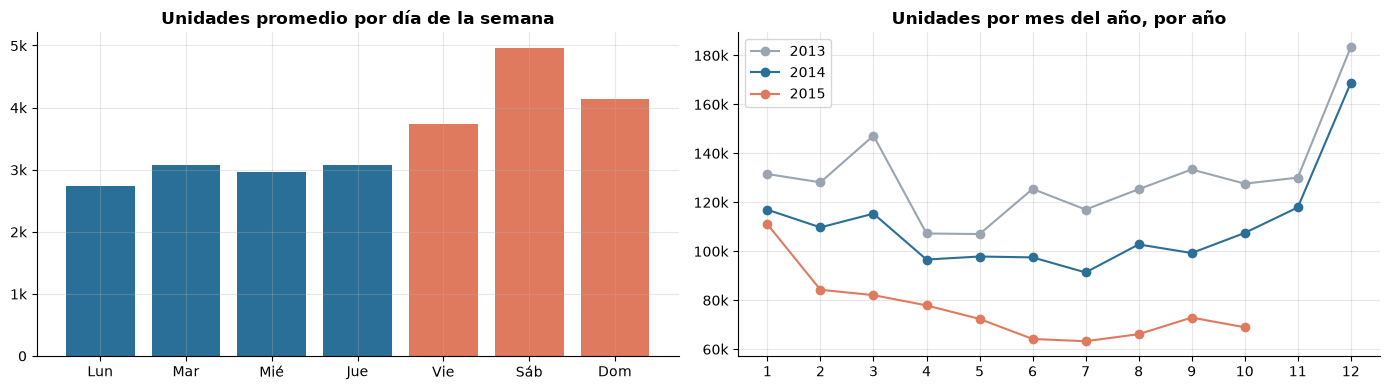

,Lun,Mar,Mié,Jue,Vie,Sáb,Dom
y,,,,,,,
2013,0.76,0.83,0.83,0.87,1.07,1.44,1.20
2014,0.77,0.86,0.84,0.89,1.05,1.42,1.17
2015,0.82,0.96,0.86,0.85,1.05,1.33,1.13


In [33]:
dow_names = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
dow = daily.groupby(daily.index.day_of_week)["units"].mean()
dow.index = dow_names
print("Índice día de la semana (promedio diario / promedio general):")
display((dow / dow.mean()).to_frame("índice").T.style.format("{:.2f}"))

moy = sales.groupby(["year", "month"])["item_cnt_day"].sum().unstack(0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(dow.index, dow.values, color=[COLOR_MAIN] * 4 + [COLOR_ACCENT] * 3)
axes[0].set_title("Unidades promedio por día de la semana"); axes[0].yaxis.set_major_formatter(thousands_formatter())
for year, color in zip(moy.columns, [COLOR_MUTED, COLOR_MAIN, COLOR_ACCENT]):
    axes[1].plot(moy.index, moy[year], marker="o", color=color, label=str(year))
axes[1].set_xticks(range(1, 13)); axes[1].set_title("Unidades por mes del año, por año")
axes[1].yaxis.set_major_formatter(thousands_formatter()); axes[1].legend()
plt.tight_layout(); save_fig(fig, "06b_ciclos_semana_mes"); plt.show()

# ¿El patrón semanal es estable a lo largo del tiempo? Índice por año
dow_year = daily.assign(y=daily.index.year, d=daily.index.day_of_week).pivot_table(index="y", columns="d", values="units")
display((dow_year.div(dow_year.mean(axis=1), axis=0)).set_axis(dow_names, axis=1).style.format("{:.2f}"))

**Interpretación: ciclos.**

- **Ciclo semanal muy marcado**: el **sábado vende 41% más** que un día promedio y el domingo 18%
  más; el lunes es el día más flojo (−23%). El patrón es **estable en los tres años** (sábado entre
  1.33 y 1.44), típico de tiendas en centros comerciales.
- **Ciclo anual**: las tres curvas por año tienen la misma forma (valle en primavera/verano, pico en
  diciembre), pero cada año está por debajo del anterior, lo que confirma la tendencia.

**Implicación:** como el objetivo es mensual, el ciclo semanal importa solo de forma indirecta: un
mes con **más fines de semana** tiende a vender más. Noviembre 2015 tiene 4 sábados y 5 domingos, y
el número de fines de semana del mes puede usarse como variable.

## 7. Análisis comparativo entre sucursales y productos

### 7a. Productos y categorías más y menos vendidos

In [34]:
names = items_full.set_index("item_id")[["item_name", "category_es"]]
item_rank = item_tot.join(names)
item_rank["item_name"] = item_rank["item_name"].str.slice(0, 55)

display(Markdown("**Top 10 productos por unidades**"))
display(item_rank.head(10)[["item_name", "category_es", "units", "revenue", "months"]])
display(Markdown("**Top 10 productos por ingreso**"))
display(item_rank.sort_values("revenue", ascending=False).head(10)[["item_name", "category_es", "units", "revenue", "months"]])

display(Markdown("**Productos menos vendidos** (unidades netas en todo el histórico)"))
low = item_rank["units"].value_counts().sort_index().head(6)
display(low.rename("n_productos").to_frame().T)
print(f"Productos con venta neta <= 0: {(item_rank.units <= 0).sum()} | con exactamente 1 unidad: {(item_rank.units == 1).sum():,}")
display(item_rank[item_rank.units <= 0].head(5)[["item_name", "category_es", "units", "revenue", "months"]])

**Top 10 productos por unidades**

,item_name,category_es,units,revenue,months
item_id,,,,,
20949,Фирменный пакет майка 1С Интерес белый (34*42)...,"Regalos - Bolsas, álbumes, mousepads","187,642.00","928,863.70",31
2808,"Diablo III [PC, Jewel, русская версия]",Juegos PC - Ediciones estándar,"17,245.00","16,852,778.42",34
3732,"Grand Theft Auto V [PS3, русские субтитры]",Juegos - PS3,"16,642.00","43,617,975.48",26
17717,Прием денежных средств для 1С-Онлайн,Servicios,"15,830.00","17,200,825.93",34
5822,Playstation Store пополнение бумажника: Карта ...,Tarjetas de pago - PSN,"14,515.00","15,408,983.12",34
3734,"Grand Theft Auto V [Xbox 360, русские субтитры]",Juegos - XBOX 360,"11,688.00","31,065,160.27",26
6675,Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1...,Consolas - PS4,"10,289.00","219,391,488.92",24
3731,"Grand Theft Auto V [PC, русские субтитры]",Juegos PC - Ediciones estándar,"10,099.00","19,983,482.89",7
1855,"Battlefield 4 [PC, русская версия]",Juegos PC - Ediciones estándar,"10,032.00","9,357,024.78",24


**Top 10 productos por ingreso**

,item_name,category_es,units,revenue,months
item_id,,,,,
6675,Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1...,Consolas - PS4,"10,289.00","219,391,488.92",24
3732,"Grand Theft Auto V [PS3, русские субтитры]",Juegos - PS3,"16,642.00","43,617,975.48",26
13443,Комплект Sony PS4 (500 Gb) Black (CUH-1108A/B0...,Consolas - PS4,"1,366.00","34,331,245.28",9
3734,"Grand Theft Auto V [Xbox 360, русские субтитры]",Juegos - XBOX 360,"11,688.00","31,065,160.27",26
3733,"Grand Theft Auto V [PS4, русские субтитры]",Juegos - PS4,"6,506.00","22,298,864.36",12
16787,"Одни из нас [PS3, русская версия]",Juegos - PS3,"9,227.00","21,907,839.08",29
3731,"Grand Theft Auto V [PC, русские субтитры]",Juegos PC - Ediciones estándar,"10,099.00","19,983,482.89",7
13405,"Комплект ""Microsoft Xbox One 500GB (Day One Ed...",Consolas - XBOX ONE,991.00,"18,125,479.52",14
17717,Прием денежных средств для 1С-Онлайн,Servicios,"15,830.00","17,200,825.93",34


**Productos menos vendidos** (unidades netas en todo el histórico)

units,-11.00,-1.00,0.00,1.00,2.00,3.00
n_productos,1,3,4,2318,1027,671


Productos con venta neta <= 0: 8 | con exactamente 1 unidad: 2,318


,item_name,category_es,units,revenue,months
item_id,,,,,
4591,"MCCARTNEY, PAUL In Red Square (Фирм.)",Música - Video musical,0.00,0.00,1
7547,VideoStudio Pro X6 IE Windows Mini-Box,Programas - Hogar y oficina,0.00,0.00,1
8515,Английский язык. 2 - 5 класс (Jewel),Programas - Educativos,0.00,14.90,1
13477,Комплект «Sony PS3 (320 Gb) (CECH-3008B)» + иг...,Consolas - PS3,0.00,"-7,592.00",2
13474,Комплект «Sony PS3 (320 Gb) (CECH-2508B) + игр...,Consolas - PS3,-1.00,"-10,398.00",1


In [35]:
cat_rank = (sales.groupby(["item_category_id", "category_es"])
            .agg(unidades=("item_cnt_day", "sum"), ingreso=("revenue", "sum"), productos=("item_id", "nunique"))
            .reset_index().sort_values("unidades", ascending=False))
display(Markdown("**Top 10 categorías por unidades**")); display(cat_rank.head(10))
display(Markdown("**10 categorías menos vendidas**")); display(cat_rank.tail(10))
cats_no_sales = set(CATEGORY_NAMES_ES) - set(cat_rank.item_category_id)
print("Categorías sin ninguna venta en el train:", sorted(cats_no_sales))

**Top 10 categorías por unidades**

,item_category_id,category_es,unidades,ingreso,productos
40,40,Cine - DVD,"634,170.00","169,944,072.69",4964
30,30,Juegos PC - Ediciones estándar,"456,540.00","257,519,291.08",751
55,55,Música - CD producción local,"348,591.00","100,022,563.57",2327
19,19,Juegos - PS3,"254,887.00","412,052,155.90",625
37,37,Cine - Blu-Ray,"203,283.00","90,478,232.84",1777
71,71,"Regalos - Bolsas, álbumes, mousepads","187,998.00","934,206.61",6
28,28,Juegos PC - Ediciones adicionales,"174,954.00","136,419,148.64",235
23,23,Juegos - XBOX 360,"169,940.00","259,615,132.35",496
20,20,Juegos - PS4,"127,319.00","373,010,312.01",157
65,65,Regalos - Juegos de mesa (compactos),"73,077.00","24,727,890.56",151


**10 categorías menos vendidas**

,item_category_id,category_es,unidades,ingreso,productos
18,18,Juegos - PS2,11.00,"3,828.20",6
27,27,Juegos MAC - Digital,8.00,"5,422.00",7
48,48,Libros - Computación,6.00,"1,654.00",5
52,52,Libros - Guías de viaje,3.00,300.00,3
0,0,PC - Auriculares/Headsets,3.00,263.40,3
50,50,Libros - Postales,3.00,58.00,2
53,53,Libros - Ficción,3.00,847.00,3
1,1,Accesorios - PS2,2.00,431.00,2
10,10,Consolas - PS2,1.00,"1,998.00",1
51,51,Libros - Divulgación,1.00,129.00,1


Categorías sin ninguna venta en el train: []


**Interpretación.**

- **Más vendidos en unidades**:
  - la bolsa de compra (187,642 unidades, presente en casi todas las compras);
  - después, videojuegos de gran lanzamiento: *Diablo III* (PC), *GTA V* (PS3, Xbox 360, PC) y
    *Battlefield 4*;
  - además, la recarga de *PlayStation Store* y el servicio de "recepción de pagos 1C-Online".
- **Más vendidos en ingreso**: la consola **PS4** domina con 219 millones de rublos (con solo
  10,289 unidades), seguida de *GTA V* y los *bundles* de PS4/Xbox One.
- **Menos vendidos**:
  - **2,318 productos vendieron una sola unidad** en todo el periodo;
  - **8 productos tienen venta neta ≤ 0** (se vendieron y se devolvieron, por ejemplo *bundles* de
    PS3).
- **Categorías**:
  - más vendidas: **Cine-DVD** (634k unidades), **Juegos PC estándar** y **Música CD local**;
  - menos vendidas: formatos obsoletos o nichos con muy pocas unidades (Juegos PS2, Consolas PS2,
    algunas categorías de libros);
  - todas las categorías tienen al menos una venta.

### 7b. Comparación del desempeño entre sucursales

Métricas por tienda: unidades e ingreso totales, ticket medio (ingreso / unidades), meses activos,
primer y último mes con ventas, y unidades promedio por mes activo (para no penalizar tiendas
abiertas recientemente).

In [36]:
shop_perf = (sales.groupby(["shop_id", "shop_label", "shop_type"])
             .agg(unidades=("item_cnt_day", "sum"), ingreso=("revenue", "sum"),
                  meses_activos=("date_block_num", "nunique"), primer_mes=("date_block_num", "min"),
                  ultimo_mes=("date_block_num", "max"), productos=("item_id", "nunique"))
             .reset_index())
shop_perf["precio_medio"] = shop_perf.ingreso / shop_perf.unidades
shop_perf["unidades_mes_activo"] = shop_perf.unidades / shop_perf.meses_activos
shop_perf["en_test"] = shop_perf.shop_id.isin(test.shop_id)
shop_perf["estado"] = np.select(
    [shop_perf.ultimo_mes < 33, shop_perf.primer_mes > 0], ["cerrada antes de oct-2015", "abrió después de ene-2013"], "activa todo el periodo")

fmt = {"unidades": "{:,.0f}", "ingreso": "{:,.0f}", "precio_medio": "{:,.0f}", "unidades_mes_activo": "{:,.0f}"}
display(shop_perf.sort_values("unidades_mes_activo", ascending=False).style.format(fmt).background_gradient(subset=["unidades_mes_activo"], cmap="Blues"))
display(shop_perf.groupby("estado").agg(tiendas=("shop_id", "count"), en_test=("en_test", "sum")))

,shop_id,shop_label,shop_type,unidades,ingreso,meses_activos,primer_mes,ultimo_mes,productos,precio_medio,unidades_mes_activo,en_test,estado
28,31,31 · Moscú,Centro comercial,"310,777","235,217,019",34,0,33,14416,757,"9,140",True,activa todo el periodo
22,25,25 · Moscú,Centro comercial,"241,919","216,479,572",34,0,33,15367,895,"7,115",True,activa todo el periodo
51,54,54 · Jimki,Centro comercial,"185,789","141,939,524",28,0,27,13863,764,"6,635",False,cerrada antes de oct-2015
25,28,28 · Moscú,Centro comercial,"184,557","159,746,337",34,0,33,12572,866,"5,428",True,activa todo el periodo
54,57,57 · Yakutsk,Calle,"152,812","119,637,154",34,0,33,12815,783,"4,494",True,activa todo el periodo
24,27,27 · Moscú,Centro comercial,"136,657","140,632,474",32,0,32,10842,"1,029","4,271",False,cerrada antes de oct-2015
39,42,42 · San Petersburgo,Centro comercial,"144,933","151,916,534",34,0,33,12034,"1,048","4,263",True,activa todo el periodo
7,9,9 · Venta itinerante,Itinerante,"15,866","16,372,837",4,9,33,1404,"1,032","3,966",False,abrió después de ene-2013
4,6,6 · Vorónezh,Calle,"100,489","98,067,454",34,0,33,11856,976,"2,956",True,activa todo el periodo
17,20,20 · Moscú,Liquidación,"5,872","6,599,924",2,21,33,746,"1,124","2,936",False,abrió después de ene-2013


,tiendas,en_test
estado,,
abrió después de ene-2013,9,7
activa todo el periodo,35,35
cerrada antes de oct-2015,13,0


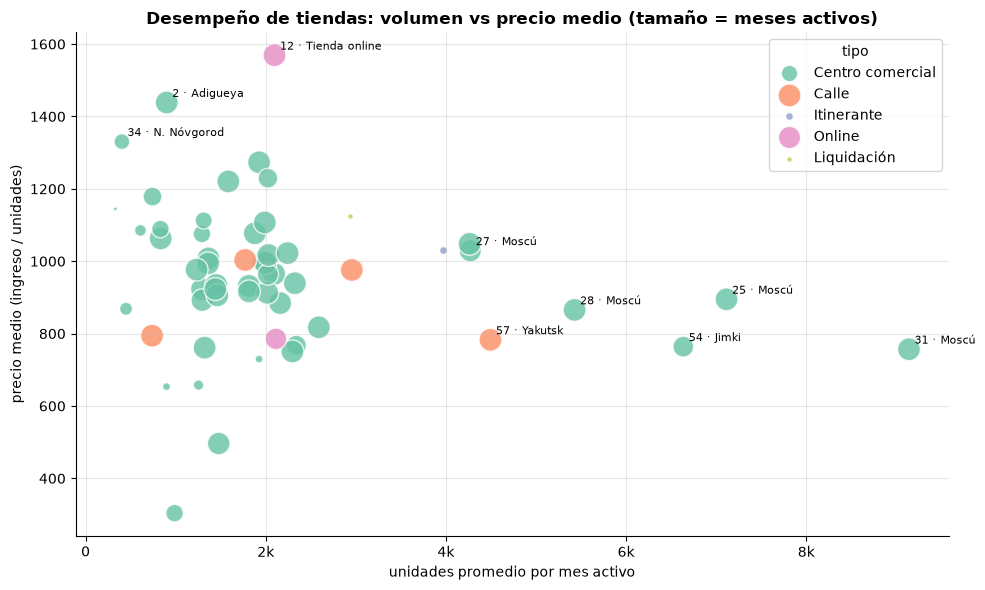

In [37]:
fig, ax = plt.subplots(figsize=(10, 6))
for t, color in zip(shop_perf.shop_type.unique(), sns.color_palette("Set2", shop_perf.shop_type.nunique())):
    d = shop_perf[shop_perf.shop_type == t]
    ax.scatter(d.unidades_mes_activo, d.precio_medio, s=d.meses_activos * 8, color=color, alpha=.8, label=t, edgecolor="white")
for _, r in shop_perf.nlargest(6, "unidades_mes_activo").iterrows():
    ax.annotate(r.shop_label, (r.unidades_mes_activo, r.precio_medio), fontsize=8, xytext=(4, 4), textcoords="offset points")
for _, r in shop_perf.nlargest(3, "precio_medio").iterrows():
    ax.annotate(r.shop_label, (r.unidades_mes_activo, r.precio_medio), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("unidades promedio por mes activo"); ax.set_ylabel("precio medio (ingreso / unidades)")
ax.set_title("Desempeño de tiendas: volumen vs precio medio (tamaño = meses activos)")
ax.xaxis.set_major_formatter(thousands_formatter()); ax.legend(title="tipo")
plt.tight_layout(); save_fig(fig, "07b_desempeno_tiendas"); plt.show()

**Interpretación.**

- **Estado de las tiendas**: 35 tiendas operaron los 34 meses, 9 abrieron después de enero 2013 y
  **13 cerraron antes de octubre 2015**. **Ninguna tienda cerrada aparece en test**, así que no
  hace falta predecirlas.
- **Volumen**: las tiendas grandes de Moscú (31, 25, 28) y la 57 de Yakutsk venden de 4,500 a 9,100
  unidades por mes activo.
- **Precio medio** (ingreso / unidades): está entre 750 y 1,250 en la mayoría de las tiendas.
  Destacan dos casos:
  - la **tienda online (12)** tiene el ticket más alto (≈1,570): vende software, consolas y envíos;
  - la **51 (Tiumén)** tiene el más bajo (≈500).
- **No hay una relación clara entre volumen y precio medio**: las tiendas grandes no son
  necesariamente más caras. El tamaño de la tienda es un nivel propio que hay que capturar por ID.
- Las tiendas **9 (itinerante)** y **20 (liquidación)** muestran un volumen alto por mes activo,
  pero solo operan en meses aislados (eventos). La **36 (Novosibirsk)** solo tiene ventas en
  octubre 2015: es una apertura reciente con un único mes de historial, y está en test.

### 7c. Outliers y comportamientos anómalos

Tres enfoques:

1. **Precios atípicos dentro de su categoría**: regla IQR (fuera de `Q3 + 1.5·IQR`) calculada por
   categoría, porque un precio "alto" para un DVD es normal para una consola.
2. **Cantidades diarias extremas** por tienda/producto.
3. **Meses anómalos por tienda**: z-score de las unidades mensuales de cada tienda contra su propia
   media.

Transacciones con precio atípico dentro de su categoría: 95,231 (3.24%)


category_es,Juegos PC - Ediciones estándar,Música - CD producción local,Programas - Hogar y oficina,Regalos - Souvenirs (colgantes),Cine - Blu-Ray,Regalos - Souvenirs,Regalos - Juegos de mesa (compactos),Libros - Material metodológico 1C
transacciones,23309,14919,5405,4716,4693,3317,3285,2551


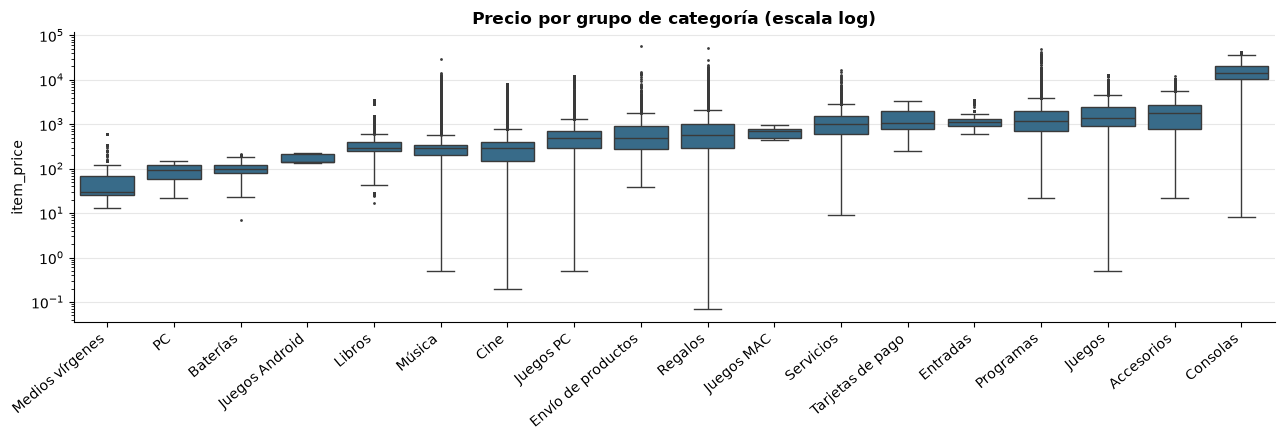

In [38]:
# 1) Precios atípicos por categoría (regla IQR)
q = sales.groupby("item_category_id")["item_price"].quantile([.25, .75]).unstack()
q.columns = ["q1", "q3"]
q["upper"] = q.q3 + 1.5 * (q.q3 - q.q1)
s_ = sales.merge(q[["upper"]], left_on="item_category_id", right_index=True)
price_out = s_[s_.item_price > s_.upper]
print(f"Transacciones con precio atípico dentro de su categoría: {len(price_out):,} ({len(price_out) / len(sales):.2%})")
display(price_out.groupby("category_es").size().sort_values(ascending=False).head(8).rename("transacciones").to_frame().T)

fig, ax = plt.subplots(figsize=(13, 4.5))
order = sales.groupby("category_group")["item_price"].median().sort_values().index
sns.boxplot(data=sales, x="category_group", y="item_price", order=order, ax=ax, color=COLOR_MAIN, fliersize=1)
ax.set_yscale("log"); ax.set_title("Precio por grupo de categoría (escala log)"); ax.set_xlabel("")
plt.xticks(rotation=40, ha="right"); plt.tight_layout(); save_fig(fig, "07c_precio_categoria"); plt.show()

In [39]:
# 2) Cantidades diarias extremas: ¿qué tiendas y productos concentran las transacciones de > 100 unidades?
big = sales[sales.item_cnt_day > 100]
print(f"Transacciones de más de 100 unidades en un día: {len(big)}")
display(big.groupby("shop_label").size().sort_values(ascending=False).head(5).rename("transacciones").to_frame().T)
display(big.groupby(["item_id"]).agg(transacciones=("date", "count"), unidades=("item_cnt_day", "sum"))
        .join(names).sort_values("unidades", ascending=False).head(8))

Transacciones de más de 100 unidades en un día: 137


shop_label,12 · Tienda online,55 · Almacén digital,42 · San Petersburgo,25 · Moscú,31 · Moscú
transacciones,42,29,11,10,8


,transacciones,unidades,item_name,category_es
item_id,,,,
20949,20,"5,650.00",Фирменный пакет майка 1С Интерес белый (34*42)...,"Regalos - Bolsas, álbumes, mousepads"
3731,10,"2,036.00","Grand Theft Auto V [PC, русские субтитры]",Juegos PC - Ediciones estándar
3732,10,"1,731.00","Grand Theft Auto V [PS3, русские субтитры]",Juegos - PS3
9248,3,"1,312.00","Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт) [...",Servicios - Entradas
9249,3,"1,309.00","Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт) У...",Entradas (Digital)
19437,4,"1,149.00","Средиземье: Тени Мордора [PC, Цифровая версия]",Juegos PC - Digital
8057,3,"1,143.00",iTunes 1500 руб.,"Tarjetas de pago (Cine, Música, Juegos)"
9242,5,"1,112.00","Билет ""ИгроМир 2014"" (на один день (отдельно -...",Entradas (Digital)


In [40]:
# 3) Meses anómalos por tienda (|z| > 3 respecto de la propia tienda)
sm = shop_month.copy()
sm["z"] = sm.groupby("shop_id")["units"].transform(lambda x: (x - x.mean()) / x.std())
anom = sm[sm.z.abs() > 3].merge(shops_full[["shop_id", "shop_label", "shop_type"]], on="shop_id")
print(f"Meses-tienda con |z| > 3: {len(anom)}")
display(anom.sort_values("z", ascending=False))

Meses-tienda con |z| > 3: 21


,shop_id,date_block_num,units,z,shop_label,shop_type
0,2,23,"1,921.00",4.22,2 · Adigueya,Centro comercial
7,21,23,"3,959.00",3.92,21 · Moscú,Centro comercial
16,47,23,"3,679.00",3.81,47 · Surgut,Centro comercial
15,42,23,"7,255.00",3.59,42 · San Petersburgo,Centro comercial
13,39,23,"1,459.00",3.42,39 · Rostov del Don,Centro comercial
11,38,11,"2,732.00",3.30,38 · Omsk,Centro comercial
20,58,11,"5,599.00",3.28,58 · Yakutsk,Centro comercial
14,42,11,"6,988.00",3.27,42 · San Petersburgo,Centro comercial
6,21,11,"3,623.00",3.24,21 · Moscú,Centro comercial
4,15,11,"4,186.00",3.20,15 · Kaluga,Centro comercial


**Interpretación: outliers y anomalías.**

1. **Precios**:
   - el 3.2% de las transacciones está por encima de `Q3 + 1.5·IQR` de su propia categoría;
   - se concentran en *Juegos PC estándar* (ediciones de lanzamiento caras) y *Música CD* (ediciones
     especiales);
   - son **outliers estadísticos, pero precios legítimos**, así que no se eliminan;
   - el gráfico por grupo confirma que el nivel de precio depende del tipo de producto (consolas
     ≈10⁴, medios vírgenes ≈10¹), por lo que **cualquier análisis de outliers de precio debe hacerse
     dentro de cada categoría**.
2. **Cantidades extremas**:
   - las 137 transacciones de más de 100 unidades en un día vienen sobre todo de la **tienda online
     (12)** y del **almacén digital (55)**: son ventas mayoristas o digitales;
   - los productos involucrados son la bolsa de compra, lanzamientos de *GTA V*, entradas a la feria
     *ИгроМир* y tarjetas de iTunes;
   - **las tiendas 12 y 55 tienen un comportamiento distinto al resto** (picos aislados enormes en
     el heatmap de 8d) y conviene tratarlas con cuidado o variables propias.
3. **Meses anómalos por tienda**:
   - de los 21 meses-tienda con |z| > 3, **17 son diciembres** (bloques 11 y 23): el "outlier" es la
     estacionalidad, no un error;
   - otro es septiembre 2015 en el almacén digital (55), que coincide con la preventa de entradas a
     *ИгроМир*;
   - los z negativos corresponden a **meses de apertura o cierre parcial** (tiendas 34, 54 y 13);
   - en el modelo conviene usar una variable de "mes de apertura/cierre" en vez de eliminar esos
     meses.

## 8. Visualizaciones clave (obligatorias)

### 8a. Serie de tiempo de ventas totales

Unidades e ingreso mensual de toda la cadena, con los picos de diciembre señalados.

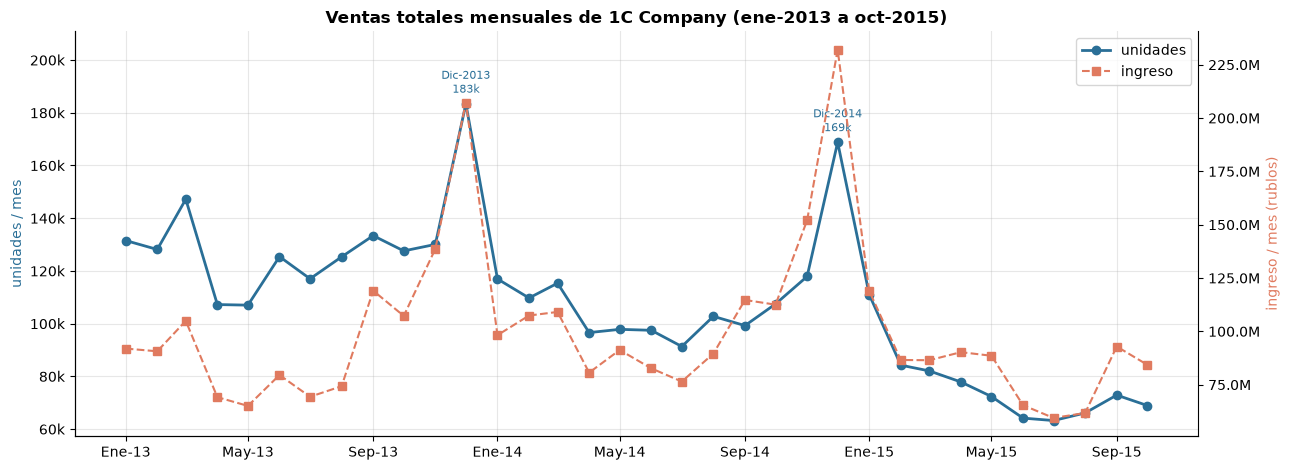

In [41]:
fig, ax1 = plt.subplots(figsize=(13, 4.8))
ax1.plot(monthly.index, monthly.units, color=COLOR_MAIN, marker="o", lw=2, label="unidades")
ax1.set_ylabel("unidades / mes", color=COLOR_MAIN); ax1.yaxis.set_major_formatter(thousands_formatter())
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly.revenue, color=COLOR_ACCENT, marker="s", lw=1.5, ls="--", label="ingreso")
ax2.set_ylabel("ingreso / mes (rublos)", color=COLOR_ACCENT); ax2.yaxis.set_major_formatter(thousands_formatter())
ax2.grid(False); ax2.spines["right"].set_visible(True)
for d in monthly.index[monthly.index.month == 12]:
    ax1.annotate(f"Dic-{d.year}\n{monthly.at[d, 'units'] / 1e3:,.0f}k", (d, monthly.at[d, "units"]),
                 xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8, color=COLOR_MAIN)
ax1.set_title("Ventas totales mensuales de 1C Company (ene-2013 a oct-2015)")
ax1.xaxis.set_major_formatter(date_formatter_es())
ax1.set_ylim(top=monthly.units.max() * 1.15)
lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax1.legend(lines, ["unidades", "ingreso"], loc="upper right")
plt.tight_layout(); save_fig(fig, "08a_serie_ventas_totales"); plt.show()

### 8b. Ventas por sucursal

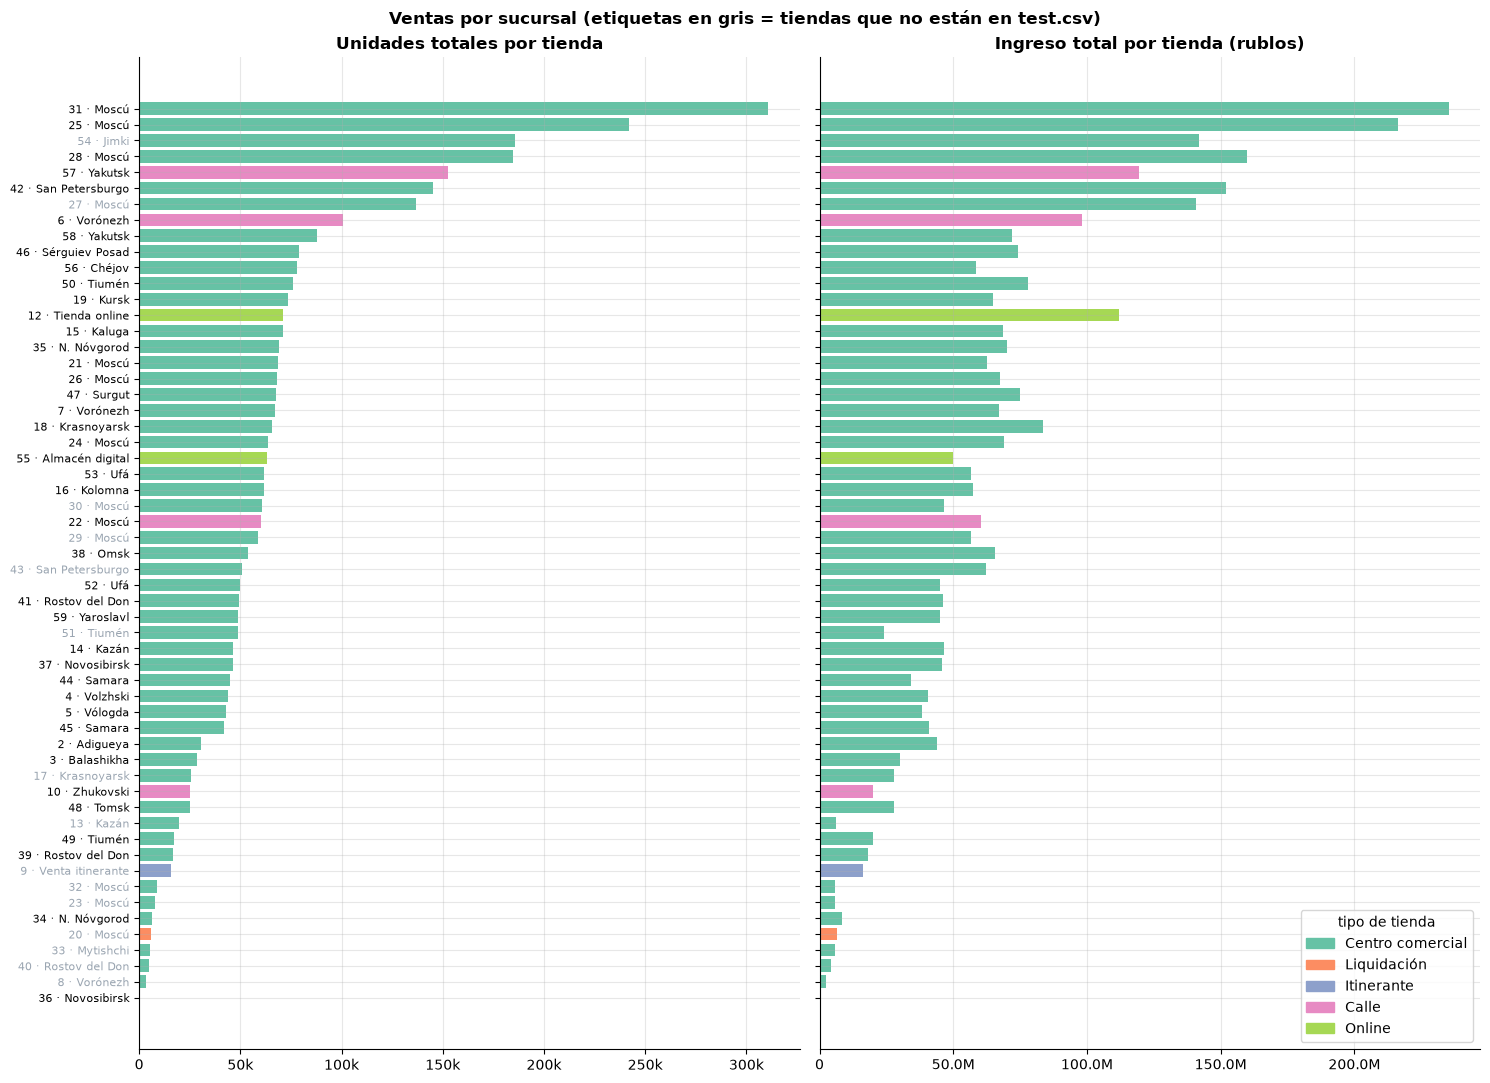

In [42]:
sp = shop_perf.sort_values("unidades")
type_colors = dict(zip(sp.shop_type.unique(), sns.color_palette("Set2", sp.shop_type.nunique())))
fig, axes = plt.subplots(1, 2, figsize=(15, 11), sharey=True)
axes[0].barh(sp.shop_label, sp.unidades, color=sp.shop_type.map(type_colors))
axes[0].set_title("Unidades totales por tienda"); axes[0].xaxis.set_major_formatter(thousands_formatter())
axes[1].barh(sp.shop_label, sp.ingreso, color=sp.shop_type.map(type_colors))
axes[1].set_title("Ingreso total por tienda (rublos)"); axes[1].xaxis.set_major_formatter(thousands_formatter())
for lbl in axes[0].get_yticklabels():
    if int(lbl.get_text().split(" ")[0]) not in set(test.shop_id):
        lbl.set_color(COLOR_MUTED)          # gris = tienda que no aparece en test
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in type_colors.values()]
axes[1].legend(handles, type_colors.keys(), title="tipo de tienda", loc="lower right")
axes[0].tick_params(axis="y", labelsize=8)
fig.suptitle("Ventas por sucursal (etiquetas en gris = tiendas que no están en test.csv)", fontweight="bold")
plt.tight_layout(); save_fig(fig, "08b_ventas_por_sucursal"); plt.show()

### 8c. Ventas por producto (top N) y por categoría

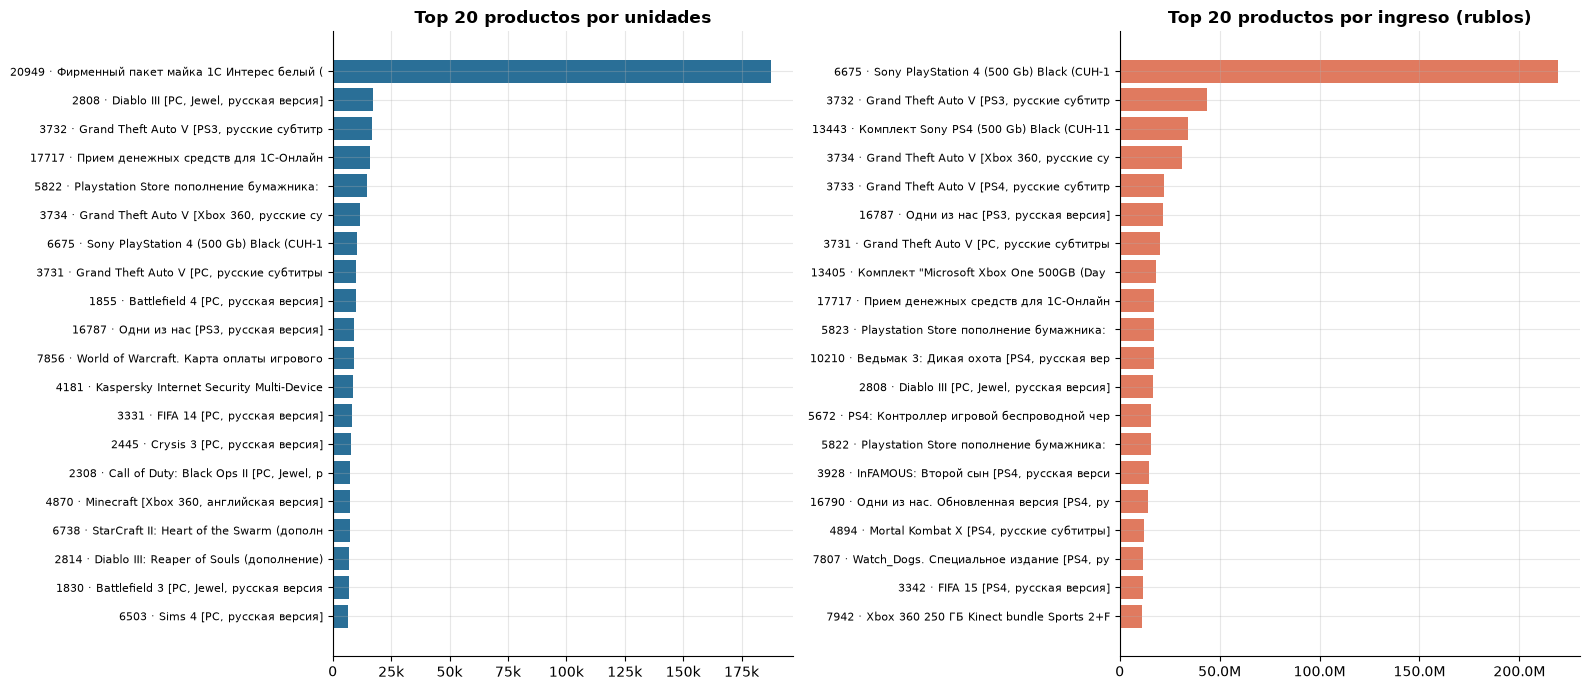

In [43]:
N = 20
top_items = item_rank.head(N).iloc[::-1]
labels = [f"{i} · {n[:40]}" for i, n in zip(top_items.index, top_items.item_name)]
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].barh(labels, top_items.units, color=COLOR_MAIN)
axes[0].set_title(f"Top {N} productos por unidades"); axes[0].xaxis.set_major_formatter(thousands_formatter())
axes[0].tick_params(axis="y", labelsize=8)

top_rev = item_rank.sort_values("revenue", ascending=False).head(N).iloc[::-1]
labels_r = [f"{i} · {n[:40]}" for i, n in zip(top_rev.index, top_rev.item_name)]
axes[1].barh(labels_r, top_rev.revenue, color=COLOR_ACCENT)
axes[1].set_title(f"Top {N} productos por ingreso (rublos)"); axes[1].xaxis.set_major_formatter(thousands_formatter())
axes[1].tick_params(axis="y", labelsize=8)
plt.tight_layout(); save_fig(fig, "08c_top_productos"); plt.show()

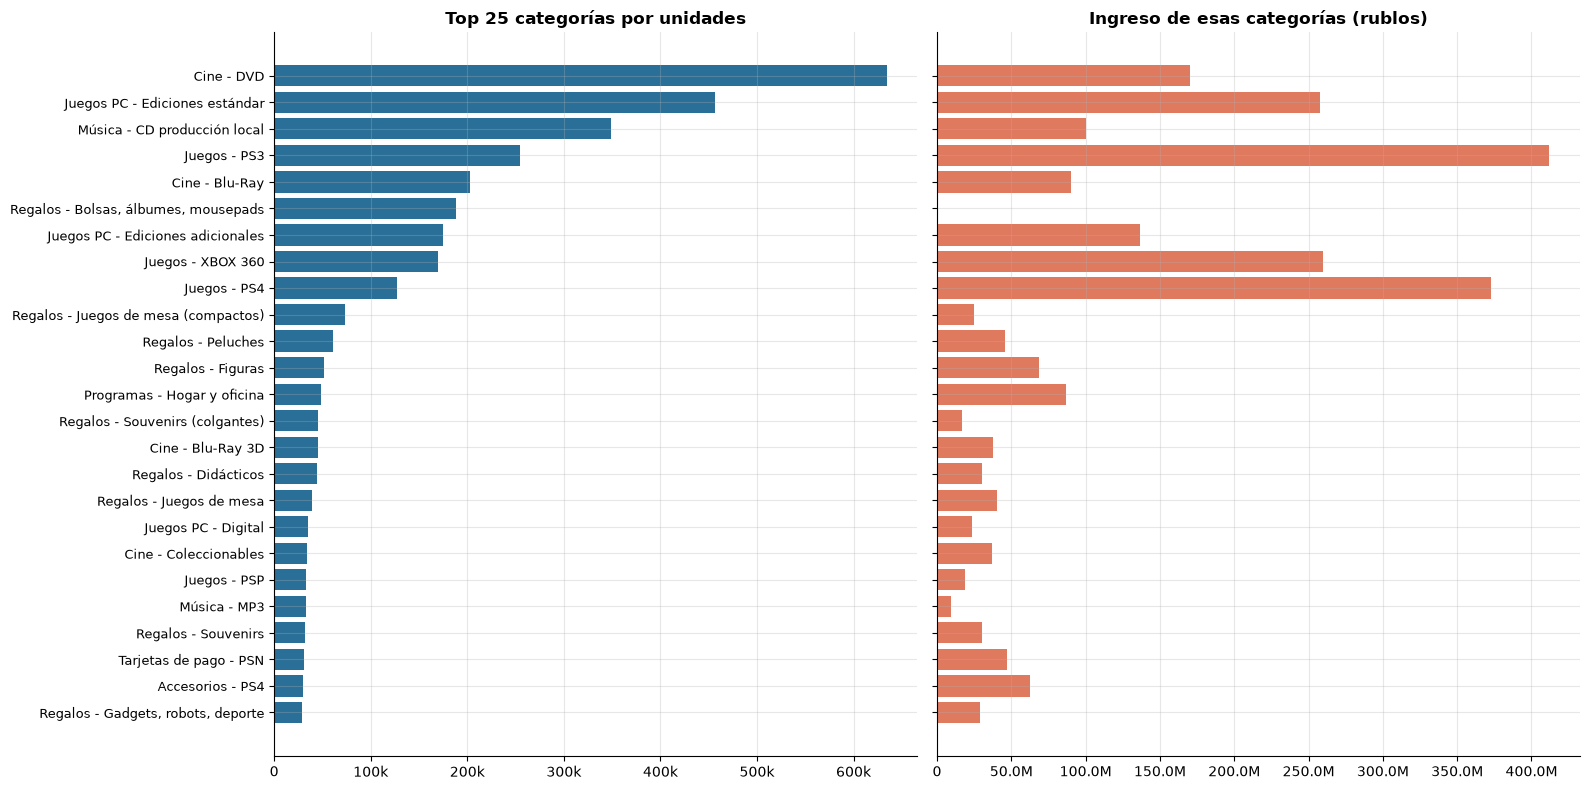

In [44]:
cr = cat_rank.head(25).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharey=True)
axes[0].barh(cr.category_es, cr.unidades, color=COLOR_MAIN)
axes[0].set_title("Top 25 categorías por unidades"); axes[0].xaxis.set_major_formatter(thousands_formatter())
axes[1].barh(cr.category_es, cr.ingreso, color=COLOR_ACCENT)
axes[1].set_title("Ingreso de esas categorías (rublos)"); axes[1].xaxis.set_major_formatter(thousands_formatter())
axes[0].tick_params(axis="y", labelsize=9)
plt.tight_layout(); save_fig(fig, "08c_ventas_por_categoria"); plt.show()

### 8d. Heatmaps: comportamiento de las ventas en el tiempo por sucursal y por categoría

- **Mes × tienda**: unidades mensuales de cada tienda. Se normaliza por fila (cada tienda contra su
  propio máximo) para que se vean aperturas, cierres y estacionalidad sin que las tiendas grandes
  opaquen a las pequeñas.
- **Mes × grupo de categoría**: participación de cada grupo en las unidades del mes, para ver qué
  segmentos crecen o se apagan.

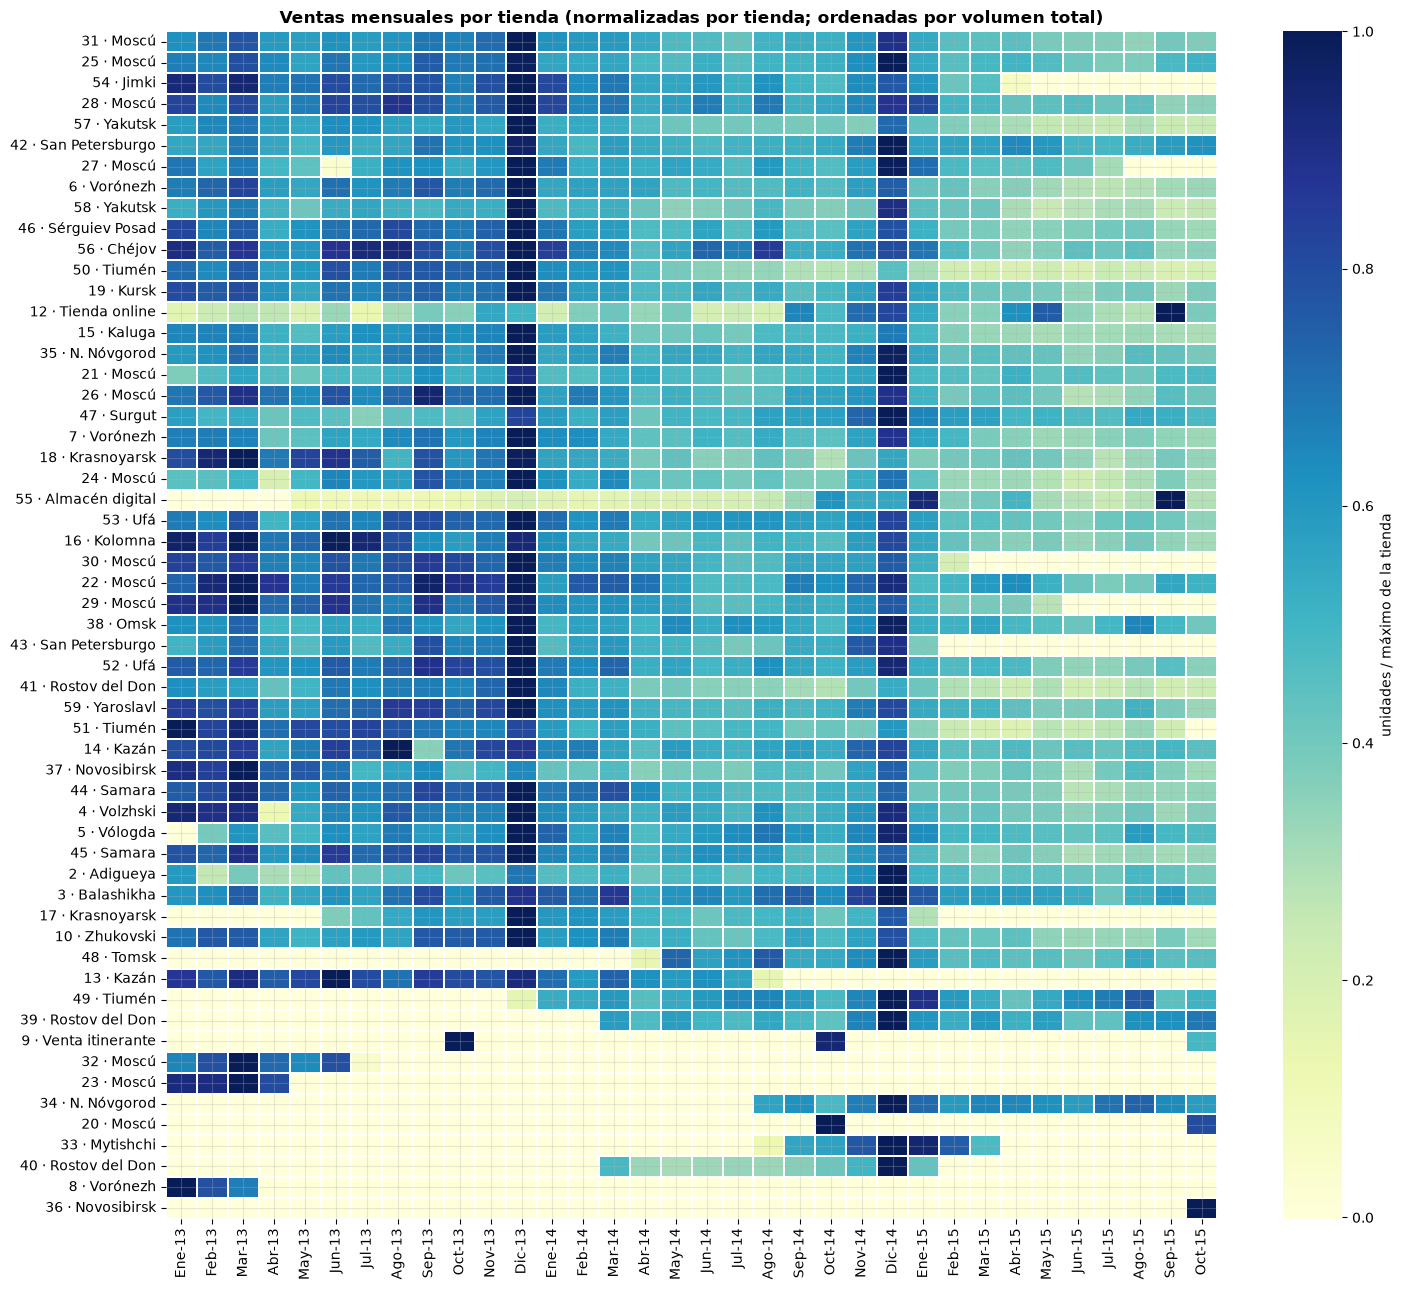

In [45]:
hm_shop = sales.pivot_table(index="shop_label", columns="date_block_num", values="item_cnt_day", aggfunc="sum", fill_value=0)
hm_shop = hm_shop.loc[shop_perf.set_index("shop_label").unidades.sort_values(ascending=False).index]
hm_shop_norm = hm_shop.div(hm_shop.max(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(15, 13))
sns.heatmap(hm_shop_norm, cmap="YlGnBu", ax=ax, cbar_kws={"label": "unidades / máximo de la tienda"}, linewidths=.2)
ax.set_xticklabels([block_label(int(t.get_text())) for t in ax.get_xticklabels()], rotation=90)
ax.set_title("Ventas mensuales por tienda (normalizadas por tienda; ordenadas por volumen total)")
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); save_fig(fig, "08d_heatmap_tienda_mes"); plt.show()

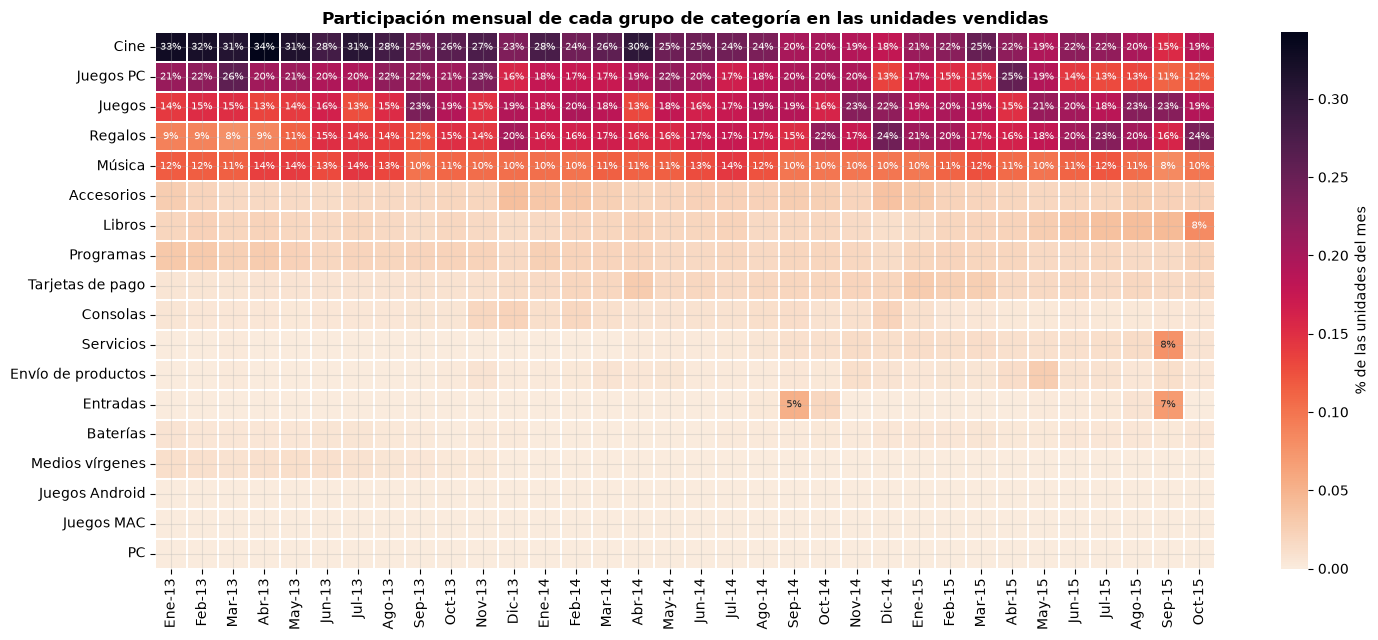

In [46]:
hm_cat = sales.pivot_table(index="category_group", columns="date_block_num", values="item_cnt_day", aggfunc="sum", fill_value=0)
hm_cat_share = hm_cat.div(hm_cat.sum(axis=0), axis=1)
hm_cat_share = hm_cat_share.loc[hm_cat.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(15, 6.5))
sns.heatmap(hm_cat_share, cmap="rocket_r", ax=ax, annot=hm_cat_share.map(lambda v: f"{v:.0%}" if v >= .05 else ""),
            fmt="", annot_kws={"fontsize": 7}, cbar_kws={"label": "% de las unidades del mes"}, linewidths=.2)
ax.set_xticklabels([block_label(int(t.get_text())) for t in ax.get_xticklabels()], rotation=90)
ax.set_title("Participación mensual de cada grupo de categoría en las unidades vendidas")
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); save_fig(fig, "08d_heatmap_categoria_mes"); plt.show()

**Interpretación de las visualizaciones clave.**

- **8a. Serie total**: resume el EDA en una imagen. Hay **tendencia decreciente en unidades**,
  **picos de diciembre** (183k y 169k) y un ingreso que se sostiene mejor que las unidades gracias
  al mayor precio medio. En 2015 no hubo repunte en septiembre–octubre comparable a 2014.
- **8b. Por sucursal**: el volumen está muy concentrado en pocas tiendas. Varias tiendas grandes
  (54 Jimki, 27 Moscú) **ya cerraron** y no están en test (etiquetas grises), por lo que su peso
  histórico no debe sesgar el pronóstico.
- **8c. Productos y categorías**: el ranking por unidades (dominado por la bolsa, juegos de PC y
  tarjetas) es muy distinto del ranking por ingreso (consolas y juegos de consola). Para predecir
  **unidades**, las categorías relevantes son Cine-DVD, Juegos PC y Música CD.
- **8d. Heatmap tienda × mes**:
  - la columna de diciembre es oscura en casi todas las tiendas: **la estacionalidad es común a toda
    la cadena**;
  - se ven las **aperturas** (zonas claras a la izquierda: 5, 17, 48, 49, 39, 34) y los **cierres**
    (zonas claras a la derecha: 13, 17, 27, 29, 30, 43, 51, 54);
  - la tienda online (12) y el almacén digital (55) tienen un patrón distinto, con picos en sep-2015.
- **8d. Heatmap categoría × mes**:
  - **Cine pierde participación** (de ≈33% a ≈19%);
  - **Regalos la gana** (de ≈9% a ≈24%);
  - Juegos sube en los meses de lanzamientos (sep–dic);
  - aparecen picos puntuales de **Entradas** y **Servicios** en sep-2014 y sep-2015 (preventa de la
    feria *ИгроМир*).

  **El mix de categorías cambia en el tiempo**, así que un modelo debe usar historia reciente por
  categoría.

## 9. Autocorrelación (ACF) y autocorrelación parcial (PACF)

- **ACF**: correlación de la serie con sus propios rezagos (incluye efectos indirectos).
- **PACF**: correlación con el rezago *k* descontando los rezagos intermedios; los rezagos
  significativos sugieren el orden *p* de un modelo AR.
- La banda sombreada es el intervalo de confianza al 95%: barras fuera de ella son significativas.

**Series analizadas** (selección representativa, como sugiere el enunciado):

| Nivel | Series | Agregación |
|---|---|---|
| Total | toda la cadena | mensual (34 obs.) y diaria (1,034 obs.) |
| Sucursal | las 3 tiendas con más ventas **que siguen activas y están en test** | mensual |
| Producto | los 3 productos con más unidades | mensual |
| Sucursal-producto | el par con más unidades + el par de mercancía más vendido (cualquier tienda y tienda física) | mensual |

Con 34 observaciones mensuales la PACF solo puede calcularse hasta el rezago 16 (`< n/2`); la ACF se
muestra hasta 18 para cubrir el rezago estacional 12. Además de las gráficas se calcula, para cada
serie, la lista de **rezagos significativos** y la prueba **ADF** de estacionariedad (H0: la serie
tiene raíz unitaria / no es estacionaria).

In [47]:
def monthly_series(mask=None) -> pd.Series:
    # Serie mensual de unidades (34 meses, rellenando con 0 los meses sin ventas)
    d = sales if mask is None else sales[mask]
    return d.groupby("date_block_num")["item_cnt_day"].sum().reindex(range(34), fill_value=0)

def acf_summary(series: pd.Series, name: str, nlags: int) -> dict:
    # Rezagos significativos (fuera del IC 95%) de ACF y PACF + p-valor de la prueba ADF
    n = len(series)
    acf_vals, acf_ci = acf(series, nlags=nlags, alpha=.05, result_object=False)
    pl = min(nlags, n // 2 - 1)
    pacf_vals, pacf_ci = pacf(series, nlags=pl, alpha=.05, method="ywm", result_object=False)
    # statsmodels devuelve el IC centrado en el valor estimado: la banda alrededor de 0 tiene
    # semiancho (ci_sup - valor); el rezago es significativo si |valor| supera ese semiancho
    sig = lambda v, ci: [k for k in range(1, len(v)) if abs(v[k]) > ci[k, 1] - v[k]]
    adf_p = adfuller(series, result_object=False)[1] if series.std() > 0 else np.nan
    return {"serie": name, "n": n, "rezagos_ACF_sig": sig(acf_vals, acf_ci), "rezagos_PACF_sig": sig(pacf_vals, pacf_ci),
            "ACF_lag1": acf_vals[1], "ACF_lag12": acf_vals[12] if nlags >= 12 else np.nan, "ADF_pvalue": adf_p}

summary = []

### 9.1 Ventas totales — nivel mensual

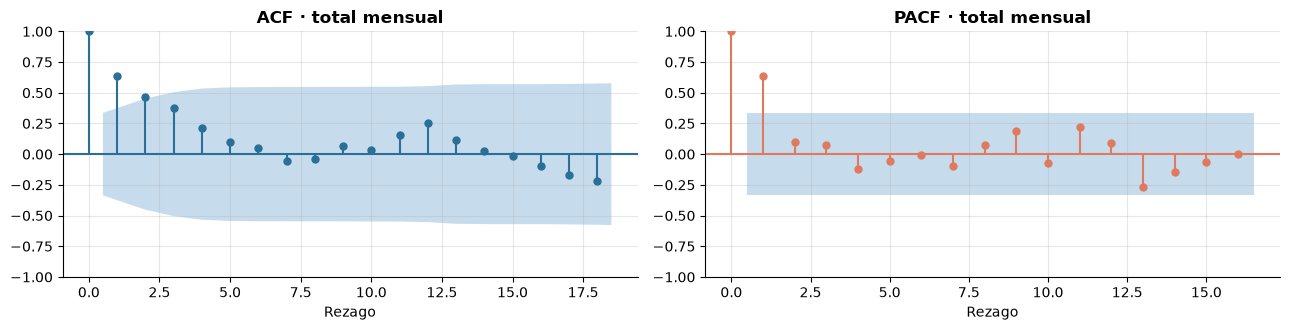

,serie,n,rezagos_ACF_sig,rezagos_PACF_sig,ACF_lag1,ACF_lag12,ADF_pvalue
0,Total · mensual,34,"[1, 2]",[1],0.64,0.26,0.15


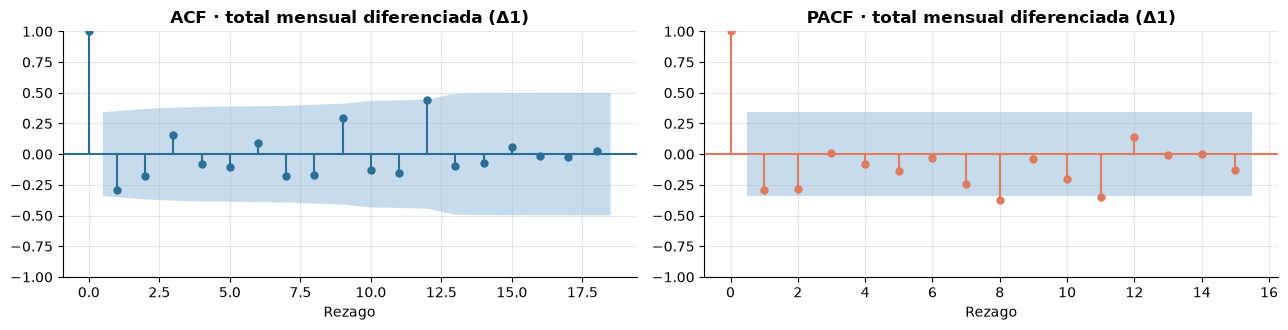

,serie,n,rezagos_ACF_sig,rezagos_PACF_sig,ACF_lag1,ACF_lag12,ADF_pvalue
0,Total · mensual Δ1,33,[12],"[8, 11]",-0.29,0.44,0.00


In [48]:
s_total_m = monthly_series()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
plot_acf_pacf(s_total_m, "total mensual", lags=18, axes=axes)
plt.tight_layout(); save_fig(fig, "09_acf_total_mensual"); plt.show()
summary.append(acf_summary(s_total_m, "Total · mensual", 18))
display(pd.DataFrame(summary[-1:]))

# Serie diferenciada (quitando tendencia) para ver mejor la estacionalidad
s_total_m_diff = s_total_m.diff().dropna()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
plot_acf_pacf(s_total_m_diff, "total mensual diferenciada (Δ1)", lags=18, axes=axes)
plt.tight_layout(); save_fig(fig, "09_acf_total_mensual_diff"); plt.show()
summary.append(acf_summary(s_total_m_diff, "Total · mensual Δ1", 18))
display(pd.DataFrame(summary[-1:]))

**Interpretación: serie total mensual.**

- **ACF**: decae de forma gradual. Son significativos los **rezagos 1 y 2** (ACF₁ = 0.64), y el
  rezago 12 sobresale (0.26) aunque no llega a la banda. Ese decaimiento lento es típico de una
  serie **con tendencia (no estacionaria)**, y lo confirma la **prueba ADF (p = 0.15 > 0.05: no se
  rechaza la raíz unitaria)**.
- **PACF**: solo el **rezago 1** es significativo, lo que sugiere un componente **AR(1)** sobre la
  serie en niveles.
- **Serie diferenciada (Δ1)**: al quitar la tendencia, la serie pasa a ser **estacionaria (ADF p <
  0.001)** y aparece claramente el **rezago 12 significativo en la ACF (0.44)**: es la
  **estacionalidad anual** (diciembre con diciembre). La PACF de la serie diferenciada muestra
  rezagos negativos en 8 y 11, propios del efecto "pico y caída" alrededor de diciembre.

**Conclusión:** la serie total se ajusta a un esquema **SARIMA con d = 1, componente AR(1) y
estacionalidad s = 12**. Con solo 34 observaciones, la estimación estacional es frágil (menos de 3
ciclos completos).

### 9.2 Ventas totales — nivel diario

Con 1,034 observaciones se usan 60 rezagos (≈ 8 semanas) para hacer visible el ciclo semanal
(rezagos 7, 14, 21, …).

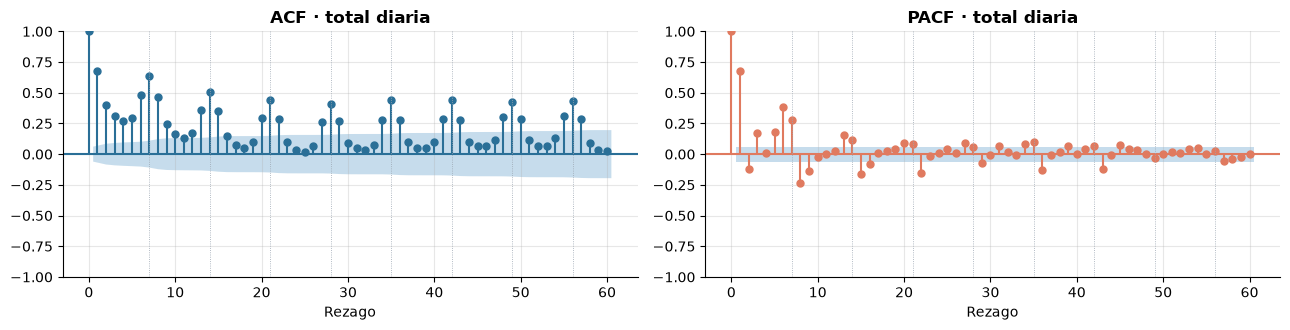

Rezagos ACF significativos: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 20, 21, 22, 27, 28, 29, 34, 35, 36, 41, 42, 43, 48, 49, 50, 55, 56, 57]
Rezagos PACF significativos: [1, 2, 3, 5, 6, 7, 8, 9, 13, 14, 15, 16, 20, 21, 22, 27, 29, 31, 34, 35, 36, 39, 42, 43, 45]
ACF rezago 7 = 0.64 | rezago 14 = 0.51 | ADF p = 0.0014


In [49]:
s_total_d = daily["units"]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
plot_acf_pacf(s_total_d, "total diaria", lags=60, axes=axes)
for ax in axes:
    for k in range(7, 61, 7): ax.axvline(k, color=COLOR_MUTED, lw=.6, ls=":")
plt.tight_layout(); save_fig(fig, "09_acf_total_diaria"); plt.show()
res = acf_summary(s_total_d, "Total · diaria", 60)
summary.append(res)
print("Rezagos ACF significativos:", res["rezagos_ACF_sig"])
print("Rezagos PACF significativos:", res["rezagos_PACF_sig"])
print(f"ACF rezago 7 = {acf(s_total_d, nlags=14, result_object=False)[7]:.2f} | rezago 14 = {acf(s_total_d, nlags=14, result_object=False)[14]:.2f} | ADF p = {res['ADF_pvalue']:.4f}")

**Interpretación: serie total diaria.**

- La ACF muestra **picos que se repiten cada 7 días** (rezagos 7, 14, 21, 28, … y sus vecinos 6 y 8)
  que decaen muy lentamente: ACF₇ = 0.64 y ACF₁₄ = 0.51. Es la huella del **ciclo semanal**
  (fines de semana fuertes) descrito en 6b-iv.
- La PACF tiene significancias en 1–3 y luego **alrededor de 7, 14, 21, 28, 35 y 42**, lo que indica
  dependencia AR de corto plazo más un **componente estacional semanal (s = 7)**.
- La prueba ADF rechaza la raíz unitaria (p = 0.001). Con 1,034 observaciones, el ciclo semanal y la
  autocorrelación de corto plazo dominan sobre la tendencia lenta.

**Conclusión:** a nivel diario la estructura es **AR de corto plazo + estacionalidad semanal**. Como
el objetivo es mensual, este ciclo se "promedia" dentro del mes, pero confirma que la composición de
días de la semana de cada mes influye en el total.

### 9.3 Ventas por sucursal (top 3 tiendas activas presentes en test)

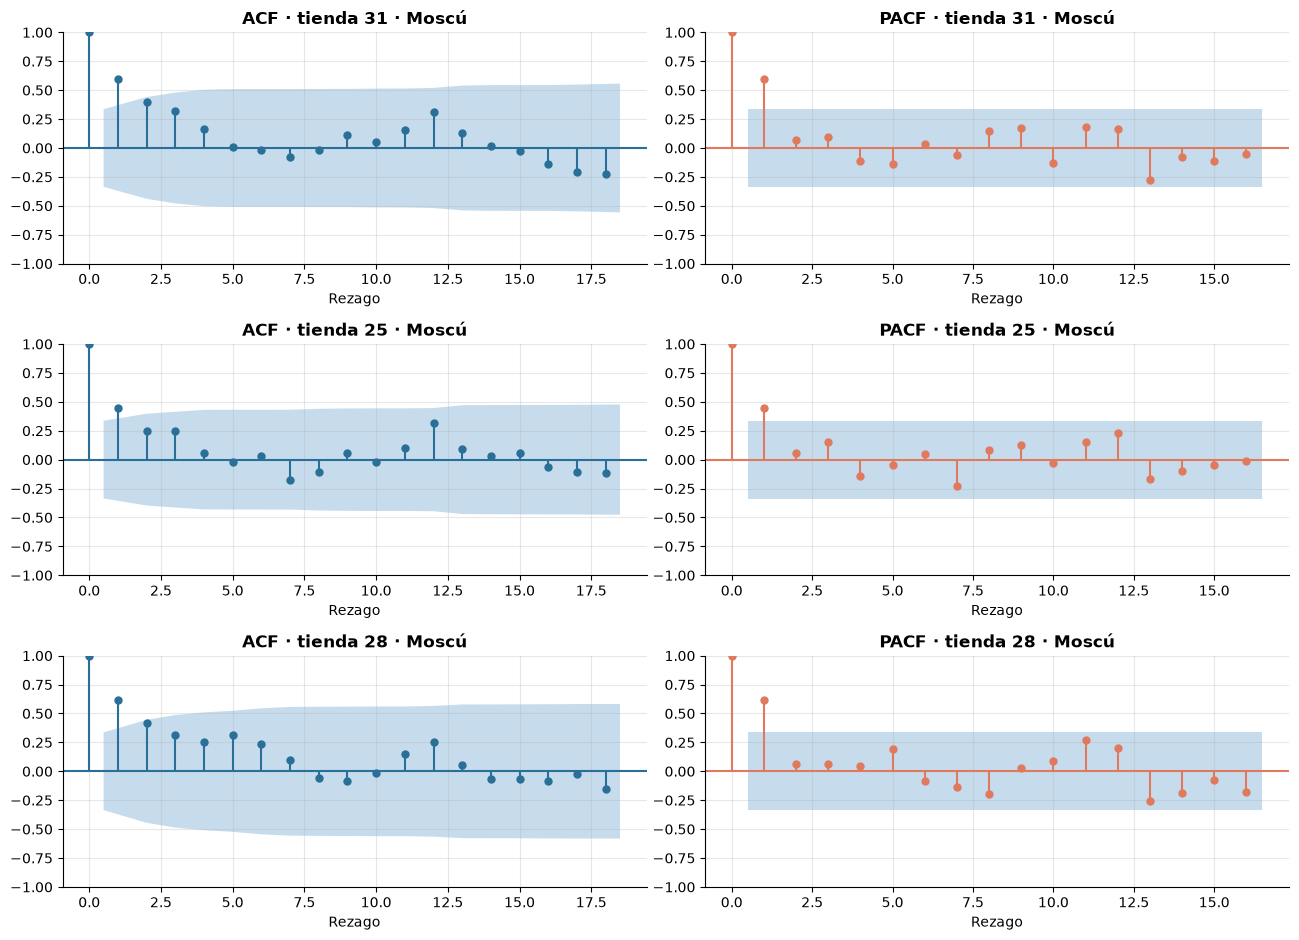

,serie,n,rezagos_ACF_sig,rezagos_PACF_sig,ACF_lag1,ACF_lag12,ADF_pvalue
0,Tienda 31 · Moscú,34,[1],[1],0.60,0.31,0.10
1,Tienda 25 · Moscú,34,[1],[1],0.44,0.31,0.01
2,Tienda 28 · Moscú,34,[1],[1],0.61,0.25,0.16


In [50]:
eligible_shops = shop_perf[(shop_perf.en_test) & (shop_perf.ultimo_mes == 33)]
top_shops = eligible_shops.nlargest(3, "unidades")
fig, axes = plt.subplots(3, 2, figsize=(13, 9.5))
for row, (_, r) in zip(axes, top_shops.iterrows()):
    s_ = monthly_series(sales.shop_id == r.shop_id)
    plot_acf_pacf(s_, f"tienda {r.shop_label}", lags=18, axes=row)
    summary.append(acf_summary(s_, f"Tienda {r.shop_label}", 18))
plt.tight_layout(); save_fig(fig, "09_acf_tiendas"); plt.show()
display(pd.DataFrame(summary[-3:]))

**Interpretación: tiendas (31, 25 y 28, todas de Moscú).**

- Las tres comparten el mismo patrón: **ACF y PACF significativas solo en el rezago 1** (ACF₁ entre
  0.44 y 0.61), con decaimiento gradual de la ACF y un repunte en el **rezago 12 (≈0.25–0.31)**
  que, con solo 34 observaciones, queda dentro de la banda de confianza.
- **Hay persistencia mes a mes** (AR(1)): el nivel de ventas del mes anterior de la tienda es el
  mejor predictor simple. Se observa una **estacionalidad anual visible pero no significativa** con
  esta muestra tan corta.
- La prueba ADF indica no estacionariedad en las tiendas 31 y 28 (p = 0.10 y 0.16), por su
  tendencia decreciente. La 25 sí rechaza la raíz unitaria (p = 0.009).

### 9.4 Ventas por producto (top 3 por unidades)

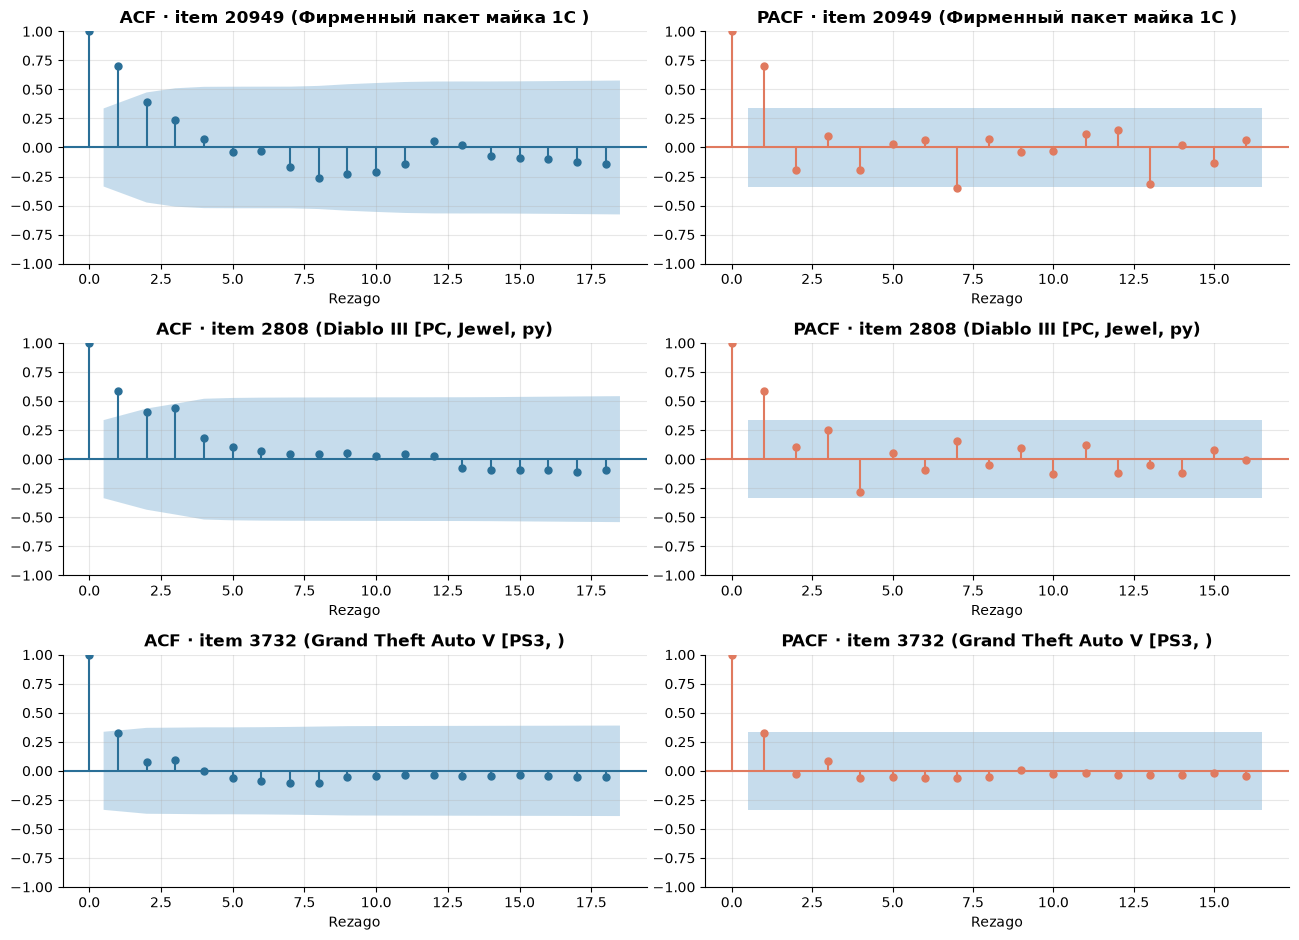

,serie,n,rezagos_ACF_sig,rezagos_PACF_sig,ACF_lag1,ACF_lag12,ADF_pvalue
0,Producto 20949,34,[1],"[1, 7]",0.70,0.06,0.10
1,Producto 2808,34,[1],[1],0.58,0.03,0.06
2,Producto 3732,34,[],[],0.32,-0.04,0.00


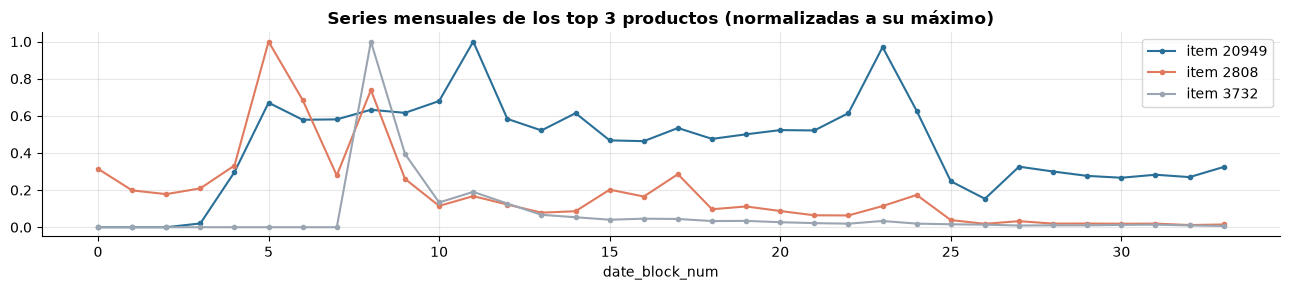

In [51]:
top3_items = item_rank.head(3)
fig, axes = plt.subplots(3, 2, figsize=(13, 9.5))
for row, (iid, r) in zip(axes, top3_items.iterrows()):
    s_ = monthly_series(sales.item_id == iid)
    plot_acf_pacf(s_, f"item {iid} ({r.item_name[:25]})", lags=18, axes=row)
    summary.append(acf_summary(s_, f"Producto {iid}", 18))
plt.tight_layout(); save_fig(fig, "09_acf_productos"); plt.show()
display(pd.DataFrame(summary[-3:]))

# Contexto: forma de las series (meses con ventas)
fig, ax = plt.subplots(figsize=(13, 3))
for iid, c in zip(top3_items.index, [COLOR_MAIN, COLOR_ACCENT, COLOR_MUTED]):
    s_ = monthly_series(sales.item_id == iid); ax.plot(s_.index, s_ / s_.max(), marker=".", color=c, label=f"item {iid}")
ax.set_title("Series mensuales de los top 3 productos (normalizadas a su máximo)"); ax.set_xlabel("date_block_num"); ax.legend()
plt.tight_layout(); plt.show()

**Interpretación: productos.**

- **Item 20949 (bolsa)** y **2808 (Diablo III PC)**: ACF₁ = 0.70 y 0.58, significativas solo en el
  rezago 1, y sin estacionalidad anual (ACF₁₂ ≈ 0). Son productos **"de catálogo"**, con venta
  persistente y suave. En la bolsa aparece también un rezago 7 en la PACF, posiblemente por el
  cambio de nivel de sus ventas entre 2014 y 2015.
- **Item 3732 (GTA V PS3)**: **ningún rezago significativo**. Su serie es un **pico de lanzamiento**
  (sep-2013) seguido de un decaimiento rápido. Esta forma, cero antes del lanzamiento y luego un
  pico, **no la describe bien un modelo AR/estacional**. Se explica mejor con variables de "meses
  desde el lanzamiento" (sección 10a).

**Conclusión:** a nivel producto **no hay estacionalidad anual significativa**: el ciclo de vida del
producto domina sobre el calendario. El rezago 1 es la señal más útil.

### 9.5 Ventas por sucursal–producto

El par con más unidades corresponde a la bolsa de compra (item 20949). Para que la selección sea
representativa se añaden los 2 pares con más unidades **excluyendo** la bolsa (categoría 71) y los
servicios de envío (categoría 9), que no son mercancía comparable: el par de mercancía con más
unidades de toda la cadena y el par de mercancía con más unidades en una **tienda física**.

,shop_id,item_id,item_category_id,item_cnt_day,item_name,category_es
0,31,20949,71,"19,934.00",Фирменный пакет майка 1С Интерес белый (34*42)...,"Regalos - Bolsas, álbumes, mousepads"
30,55,7967,34,"2,365.00",Xbox LIVE: GOLD карта подписки 3 месяца [Цифро...,Tarjetas de pago - Live! (Digital)
55,31,5822,35,"1,293.00",Playstation Store пополнение бумажника: Карта ...,Tarjetas de pago - PSN


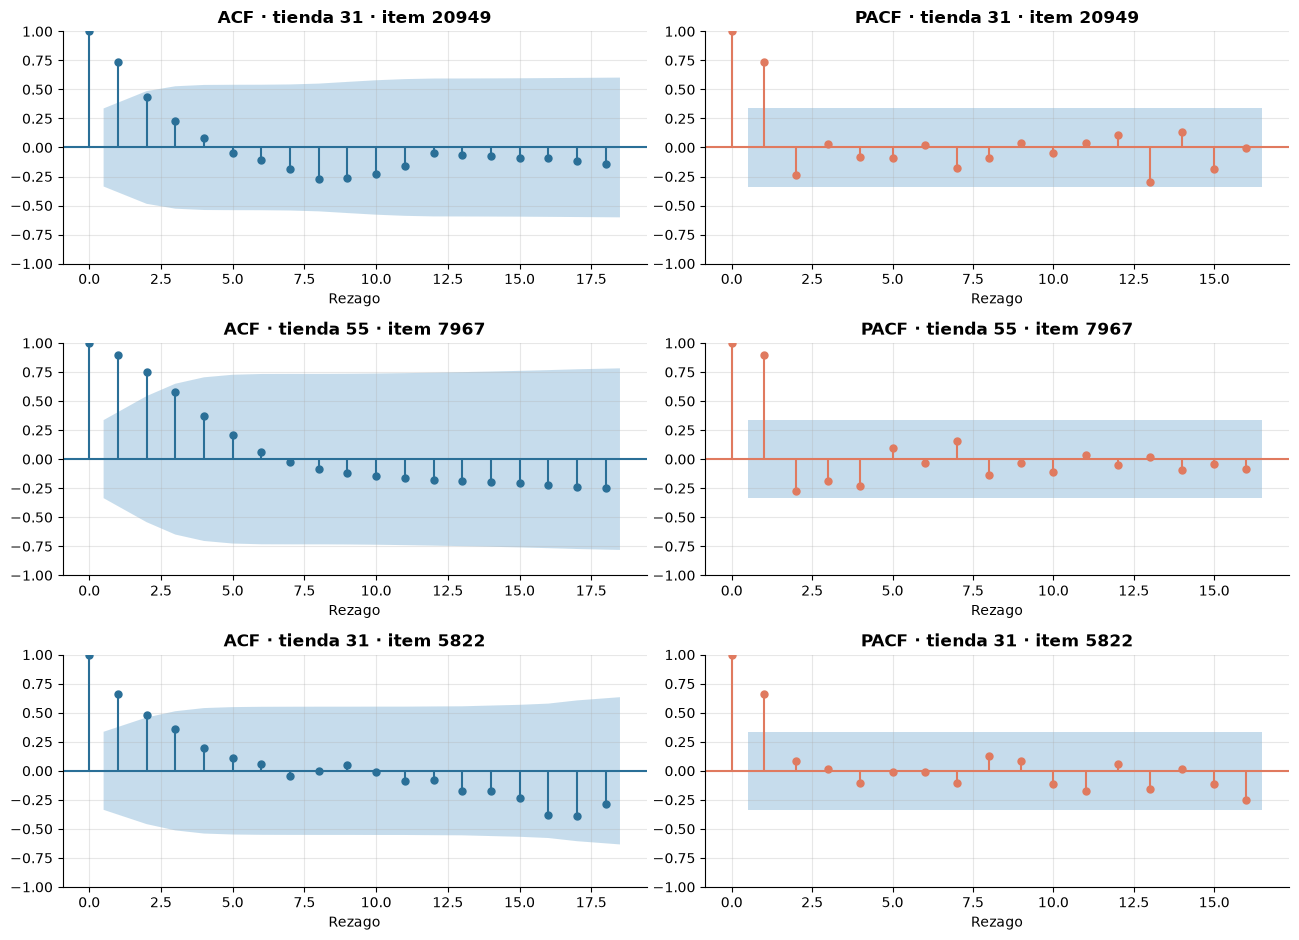

,serie,n,rezagos_ACF_sig,rezagos_PACF_sig,ACF_lag1,ACF_lag12,ADF_pvalue
0,Tienda 31 · item 20949,34,[1],[1],0.74,-0.05,0.14
1,Tienda 55 · item 7967,34,"[1, 2]",[1],0.90,-0.18,0.44
2,Tienda 31 · item 5822,34,"[1, 2]",[1],0.66,-0.08,0.08


In [52]:
pair_tot = sales.groupby(["shop_id", "item_id", "item_category_id"])["item_cnt_day"].sum().sort_values(ascending=False).reset_index()
first_pair = pair_tot.iloc[[0]]
merch = pair_tot[~pair_tot.item_category_id.isin([9, 71])]
physical = set(shops_full.loc[shops_full.shop_type.isin(["Centro comercial", "Calle"]), "shop_id"])
sel_pairs = pd.concat([first_pair, merch.head(1), merch[merch.shop_id.isin(physical)].head(1)]).join(names, on="item_id")
display(sel_pairs)

fig, axes = plt.subplots(3, 2, figsize=(13, 9.5))
for row, (_, r) in zip(axes, sel_pairs.iterrows()):
    s_ = monthly_series((sales.shop_id == r.shop_id) & (sales.item_id == r.item_id))
    plot_acf_pacf(s_, f"tienda {r.shop_id} · item {r.item_id}", lags=18, axes=row)
    summary.append(acf_summary(s_, f"Tienda {r.shop_id} · item {r.item_id}", 18))
plt.tight_layout(); save_fig(fig, "09_acf_tienda_producto"); plt.show()
display(pd.DataFrame(summary[-3:]))

**Interpretación: pares tienda–producto.**

- Los tres pares (bolsa en la tienda 31; tarjeta Xbox Live Gold en el almacén digital 55; recarga
  PSN en la tienda 31) muestran **alta persistencia de corto plazo**: ACF₁ entre 0.66 y 0.90,
  significativa en rezagos 1–2, y **PACF significativa solo en el rezago 1**. Son procesos de tipo
  **AR(1)**.
- **No hay estacionalidad a nivel par**: ACF₁₂ es negativa o cercana a 0 en los tres casos.
- Los pares elegidos son **los más vendidos y estables**. El par típico (2 meses con venta de 34) es
  casi todo ceros y no tiene estructura autorregresiva útil por sí solo. Por eso, en el modelo
  conviene combinar los rezagos del par con rezagos agregados del **producto**, la **tienda** y la
  **categoría**.

### 9.6 Resumen de ACF / PACF

In [53]:
acf_tbl = pd.DataFrame(summary).set_index("serie")
display(acf_tbl.style.format({"ACF_lag1": "{:.2f}", "ACF_lag12": "{:.2f}", "ADF_pvalue": "{:.3f}"}))

,n,rezagos_ACF_sig,rezagos_PACF_sig,ACF_lag1,ACF_lag12,ADF_pvalue
serie,,,,,,
Total · mensual,34,"[1, 2]",[1],0.64,0.26,0.151
Total · mensual Δ1,33,[12],"[8, 11]",-0.29,0.44,0.000
Total · diaria,1034,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 20, 21, 22, 27, 28, 29, 34, 35, 36, 41, 42, 43, 48, 49, 50, 55, 56, 57]","[1, 2, 3, 5, 6, 7, 8, 9, 13, 14, 15, 16, 20, 21, 22, 27, 29, 31, 34, 35, 36, 39, 42, 43, 45]",0.68,0.17,0.001
Tienda 31 · Moscú,34,[1],[1],0.60,0.31,0.101
Tienda 25 · Moscú,34,[1],[1],0.44,0.31,0.009
Tienda 28 · Moscú,34,[1],[1],0.61,0.25,0.160
Producto 20949,34,[1],"[1, 7]",0.70,0.06,0.103
Producto 2808,34,[1],[1],0.58,0.03,0.058
Producto 3732,34,[],[],0.32,-0.04,0.000


**Respuestas a las preguntas del enunciado.**

**i. ¿Existen correlaciones significativas a diferentes rezagos?**

Sí:

- **El rezago 1 es significativo en casi todas las series** (total, tiendas, productos y pares), con
  ACF₁ entre 0.44 y 0.90 y la PACF con corte en el rezago 1. **Las ventas del mes anterior son la
  señal más fuerte** y sugieren términos **AR(1)**.
- En la serie diaria hay significancia en muchos rezagos, sobre todo en **múltiplos de 7**.

**ii. ¿Se observa estacionalidad reflejada en patrones repetitivos?**

Sí, pero depende del nivel de agregación:

| Nivel | Estacionalidad |
|---|---|
| Total diario | **Semanal (s = 7)**, muy fuerte |
| Total mensual | **Anual (s = 12)**: significativa en la serie diferenciada (ACF₁₂ = 0.44) |
| Tienda mensual | Anual **visible pero no significativa** (ACF₁₂ ≈ 0.25–0.31), por la muestra corta |
| Producto / par | **No hay**: domina el ciclo de vida del producto |

**Implicaciones para el modelo:**

- usar **rezagos 1, 2, 3 y 12** del objetivo, a nivel par, producto, tienda y categoría;
- incluir **variables de mes del año** (diciembre y noviembre);
- tener en cuenta que las series agregadas **no son estacionarias** (tendencia decreciente).

## 10. Insights y conclusiones del EDA

### 10a. Variables que afectan directamente las ventas

Se cuantifican los factores observados en las secciones anteriores sobre la tabla mensual
tienda–producto (la granularidad del objetivo):

1. **Antigüedad del producto** (meses desde su primera venta): ¿los productos venden más al
   lanzarse?
2. **Mes del año** (efecto diciembre).
3. **Categoría** y **tienda** (cuánta variación del objetivo explican).
4. **Precio** (relación precio–unidades).
5. **Historial reciente** (rezago 1 del propio par).

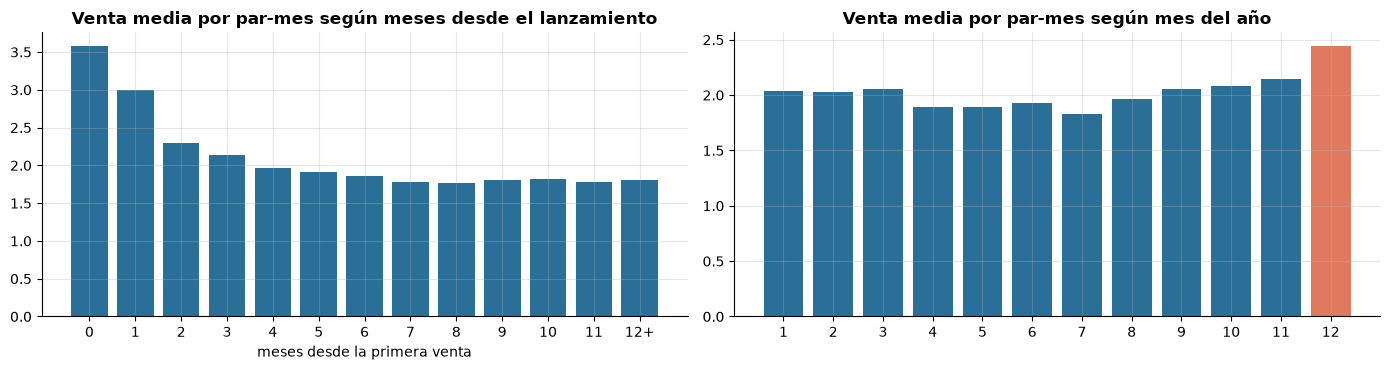

Mes de lanzamiento vs. 6 meses después: 3.58 vs 1.85 unidades (x1.9)


In [54]:
mp = monthly_pairs.merge(items_full[["item_id", "item_category_id", "category_group"]], on="item_id")
first_sale = sales.groupby("item_id")["date_block_num"].min().rename("first_block")
mp = mp.join(first_sale, on="item_id")
mp["item_age"] = mp.date_block_num - mp.first_block
mp["month"] = mp.date_block_num % 12 + 1
mp["y"] = mp.item_cnt_month.clip(0, 20)                      # objetivo tal como lo evalúa Kaggle

# 1) Antigüedad del producto: excluimos productos ya existentes al inicio (first_block = 0, edad real desconocida)
age = mp[mp.first_block > 0].groupby(mp.item_age.clip(upper=12))["y"].mean()
# 2) Mes del año
by_month = mp.groupby("month")["y"].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].bar(age.index.astype(int).astype(str).str.replace("12", "12+"), age.values, color=COLOR_MAIN)
axes[0].set_title("Venta media por par-mes según meses desde el lanzamiento"); axes[0].set_xlabel("meses desde la primera venta")
axes[1].bar(by_month.index, by_month.values, color=[COLOR_ACCENT if m == 12 else COLOR_MAIN for m in by_month.index])
axes[1].set_title("Venta media por par-mes según mes del año"); axes[1].set_xticks(range(1, 13))
plt.tight_layout(); save_fig(fig, "10a_factores"); plt.show()
print(f"Mes de lanzamiento vs. 6 meses después: {age.iloc[0]:.2f} vs {age.loc[6]:.2f} unidades (x{age.iloc[0] / age.loc[6]:.1f})")

In [55]:
# 3) Razón de correlación (eta²): % de la varianza del objetivo explicada por cada factor categórico
def eta_squared(cat: pd.Series, y: pd.Series) -> float:
    g = y.groupby(cat)
    return float((g.count() * (g.mean() - y.mean()) ** 2).sum() / ((y - y.mean()) ** 2).sum())

# 4) Precio medio del par-mes y 5) rezago 1 del par
mp = mp.sort_values(["shop_id", "item_id", "date_block_num"])
mp["price"] = mp.revenue_month / mp.item_cnt_month.replace(0, np.nan)
full_lag = mp.set_index(["date_block_num", "shop_id", "item_id"])["y"]
mp["y_lag1"] = full_lag.reindex(pd.MultiIndex.from_arrays([mp.date_block_num - 1, mp.shop_id, mp.item_id])).fillna(0).values

factors = pd.Series({
    "categoría (84)": eta_squared(mp.item_category_id, mp.y),
    "grupo de categoría (18)": eta_squared(mp.category_group, mp.y),
    "tienda": eta_squared(mp.shop_id, mp.y),
    "mes del año": eta_squared(mp.month, mp.y),
    "antigüedad del producto (0-12+)": eta_squared(mp.item_age.clip(upper=12), mp.y),
}).sort_values(ascending=False)
display(factors.to_frame("eta² (varianza explicada)").style.format("{:.2%}"))

print(f"Correlación de Spearman precio vs unidades (par-mes): {mp[['price', 'y']].dropna().corr(method='spearman').iloc[0, 1]:+.3f}")
print(f"Correlación de Pearson y_t vs y_(t-1) del mismo par:  {mp[['y', 'y_lag1']].corr().iloc[0, 1]:+.3f}")

,eta² (varianza explicada)
categoría (84),12.90%
grupo de categoría (18),6.72%
antigüedad del producto (0-12+),2.91%
tienda,1.93%
mes del año,0.34%


Correlación de Spearman precio vs unidades (par-mes): +0.158
Correlación de Pearson y_t vs y_(t-1) del mismo par:  +0.523


**Variables que afectan directamente las ventas.**

| Factor | Evidencia | Fuerza |
|---|---|---|
| **Historial reciente del par** (rezago 1) | Correlación 0.52 entre y(t) y y(t−1); ACF₁ significativa en todas las series | **Muy alta** |
| **Categoría del producto** | Explica el 12.9% de la varianza del objetivo (η²), el doble que el grupo de categoría (6.7%) | **Alta** |
| **Antigüedad del producto** | En el mes de lanzamiento un par vende en promedio 3.6 unidades, contra 1.85 seis meses después (**1.9 veces más**) | Alta para productos nuevos |
| **Tienda** | η² = 1.9%; nivel base muy distinto entre tiendas (5 veces entre la 31 y la mediana) | Media |
| **Mes del año** | η² de solo 0.3% a nivel par, pero diciembre es +60% en la serie total y la venta media por par sube ≈20% | Media (agregada) |
| **Precio** | Spearman +0.16 entre precio y unidades (par-mes): **no hay elasticidad negativa visible**, porque los productos caros son lanzamientos muy demandados | Baja/confusa |
| **Tendencia temporal** | −1.8% de unidades por mes; caen las ventas por tienda y el número de productos activos | Media |

Nota: η² mide la varianza **entre** grupos sobre los pares-mes con venta. Es baja porque la mayor
parte de la varianza es ruido individual de cada par, y por eso los rezagos propios del par son tan
importantes. Las medias por antigüedad y por mes están **condicionadas a que el par haya vendido**
en ese mes.

### 10b. Patrones útiles para el modelo de forecasting y cobertura de `test.csv`

Para predecir noviembre 2015 es clave saber **qué información histórica existe** para cada par de
test. Se clasifica cada fila de test en tres grupos:

- **Par con historial**: ese producto ya se vendió en esa tienda.
- **Producto conocido, par nuevo**: el producto se vendió en otras tiendas, pero nunca en esa.
- **Producto nuevo**: el producto nunca aparece en el train.

(Las tiendas ya están unificadas, así que los IDs 57/58/10 incluyen el historial de 0/1/11.)

In [56]:
pairs_hist = set(zip(sales.shop_id, sales.item_id))
items_hist = set(sales.item_id)
t = test.copy()
t["grupo"] = np.select(
    [[p in pairs_hist for p in zip(t.shop_id, t.item_id)], t.item_id.isin(items_hist)],
    ["Par con historial", "Producto conocido, par nuevo"], "Producto nuevo")
cov_tbl = t["grupo"].value_counts().to_frame("filas")
cov_tbl["%"] = cov_tbl.filas / len(t)
display(cov_tbl.style.format({"filas": "{:,}", "%": "{:.1%}"}))

print(f"Tiendas en test: {t.shop_id.nunique()} | productos en test: {t.item_id.nunique():,} | "
      f"filas = tiendas x productos? {t.shop_id.nunique() * t.item_id.nunique() == len(t)}")
print(f"Productos nuevos en test: {(~pd.Series(t.item_id.unique()).isin(items_hist)).sum()}")

# ¿Cuántos pares de test vendieron algo en el último mes (oct-2015)?
last = set(zip(*sales[sales.date_block_num == 33][["shop_id", "item_id"]].values.T))
t["vendio_oct15"] = [p in last for p in zip(t.shop_id, t.item_id)]
print(f"Pares de test con ventas en oct-2015: {t.vendio_oct15.mean():.1%}")
print(f"Tiendas de test sin ventas en oct-2015: {sorted(set(t.shop_id) - set(sales[sales.date_block_num == 33].shop_id))}")

# Categorías de los productos nuevos
new_items = t[t.grupo == "Producto nuevo"].drop_duplicates("item_id").merge(items_full, on="item_id")
display(new_items.category_group.value_counts().head(6).rename("productos nuevos").to_frame().T)

,filas,%
grupo,,
Par con historial,"111,471",52.0%
"Producto conocido, par nuevo","87,483",40.8%
Producto nuevo,"15,246",7.1%


Tiendas en test: 42 | productos en test: 5,100 | filas = tiendas x productos? True
Productos nuevos en test: 363
Pares de test con ventas en oct-2015: 13.4%
Tiendas de test sin ventas en oct-2015: []


category_group,Cine,Regalos,Música,Juegos,Libros,Juegos PC
productos nuevos,74,67,66,45,44,38


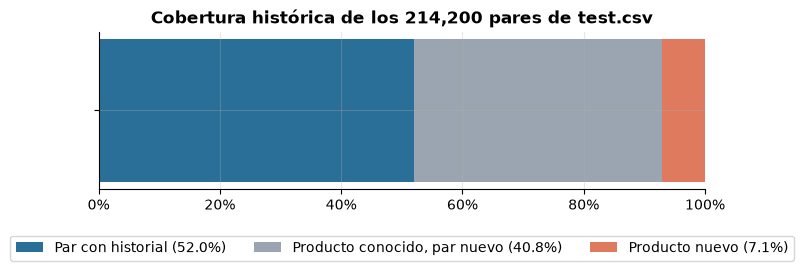

In [57]:
fig, ax = plt.subplots(figsize=(8, 3))
left = 0
for (g, row), c in zip(cov_tbl.iterrows(), [COLOR_MAIN, COLOR_MUTED, COLOR_ACCENT]):
    ax.barh([""], [row["%"]], left=left, color=c, label=f"{g} ({row['%']:.1%})")
    left += row["%"]
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set_title("Cobertura histórica de los 214,200 pares de test.csv"); ax.legend(loc="upper center", bbox_to_anchor=(.5, -.25), ncol=3)
plt.tight_layout(); save_fig(fig, "10b_cobertura_test"); plt.show()

**Patrones útiles para el forecasting y cobertura de test.**

**Cobertura de `test.csv`:**

| Grupo | Filas | % | Información disponible |
|---|---|---|---|
| Par con historial | 111,471 | **52.0%** | Rezagos propios del par |
| Producto conocido, par nuevo | 87,483 | **40.8%** | Rezagos del producto en otras tiendas, de la tienda y de la categoría |
| Producto nuevo | 15,246 | **7.1%** (363 productos) | Solo categoría, tienda y el patrón de lanzamiento |

- Solo el **52%** de los pares a predecir tiene historial en esa tienda. Aun así, el 100% de las
  **tiendas** de test tiene historial y ventas en octubre 2015.
- Solo el **13.4%** de los pares de test vendió algo en octubre 2015: la gran mayoría de las
  predicciones correctas estará **cerca de 0**.
- Los 363 productos nuevos son sobre todo de Cine, Regalos, Música y Juegos: **lanzamientos de
  noviembre**. Para ellos, el patrón "un producto vende más en su primer mes" es clave.

**Patrones a llevar al modelo:**

1. Entrenar sobre una **cuadrícula mes × tienda × producto con ceros**, igual que test, y no solo
   sobre los pares con venta.
2. **Rezagos** del objetivo (1, 2, 3, 6 y 12) a nivel par, producto, tienda y categoría.
3. **Antigüedad del producto** y meses desde la primera venta en la tienda.
4. **Mes del año**: noviembre está por encima de la media; también el número de fines de semana del
   mes.
5. **Tendencia** decreciente: dar más peso a la historia reciente.
6. **Recortar el objetivo a [0, 20]**.
7. Usar el **tipo de tienda** (online/digital) como variable, o tratar esas tiendas aparte.

### 10c. Calidad del dataset y preparación para las siguientes etapas

Se guarda el dataset mensual tienda–producto limpio en `data/processed/`, que es la base para la
etapa de forecasting.

In [58]:
monthly_out = monthly_pairs.rename(columns={"revenue_month": "revenue"})
monthly_out.to_csv(PROCESSED_DATA_DIR / "monthly_shop_item.csv", index=False)
print(f"Guardado: {PROCESSED_DATA_DIR / 'monthly_shop_item.csv'}  ({len(monthly_out):,} filas)")
display(monthly_out.head())

Guardado: C:\Users\cesar\OneDrive\Escritorio\maestria\Segundo año\Cuarto trimeste\Product Development\proyecto1\Predict Future Sales\data\processed\monthly_shop_item.csv  (1,609,123 filas)


,date_block_num,shop_id,item_id,item_cnt_month,revenue
0,0,2,27,1.00,"2,499.00"
1,0,2,33,1.00,499.00
2,0,2,317,1.00,299.00
3,0,2,438,1.00,299.00
4,0,2,471,2.00,798.00


**Conclusión sobre la calidad y la preparación del dataset.**

**Calidad: alta, con pocas correcciones necesarias.**

- 0 nulos, integridad referencial completa, `date_block_num` consistente, calendario sin huecos.
- Correcciones aplicadas, menos del 0.001% de las filas:

| Corrección | Filas |
|---|---|
| Duplicados exactos eliminados | 6 |
| Precio negativo imputado | 1 |
| Transacciones extremas eliminadas | 2 |
| Tiendas duplicadas unificadas (0→57, 1→58, 11→10) | 3 IDs |

- Devoluciones conservadas (0.25% de las filas) para trabajar con la venta neta.
- La limpieza está encapsulada en `predict_future_sales.dataset.clean_sales()`, y se verificó que da
  el mismo resultado que el paso a paso de este notebook.

**Retos para el modelado** (son propios del problema, no errores de los datos):

1. **Dispersión extrema**: el 96% de las celdas mes × tienda × producto están vacías.
2. **Productos nuevos y pares sin historial** en el 48% de test.
3. **Tendencia decreciente** y **estacionalidad de diciembre** con solo 34 meses de historia.
4. **Tiendas con comportamiento especial** (online 12, digital 55, itinerante 9, liquidación 20,
   apertura reciente 36).
5. Textos en ruso: los nombres de producto podrían aportar variables (plataforma, edición), pero
   requieren procesamiento de texto.

**Artefactos generados para las siguientes etapas:**

- `data/interim/sales_clean_enriched.csv`: transacciones limpias con catálogos y columnas derivadas.
- `data/processed/monthly_shop_item.csv`: objetivo mensual por par (base para crear la cuadrícula y
  los rezagos).
- `reports/figures/`: todas las figuras del EDA.

El dataset está **listo para la etapa de feature engineering y forecasting**.